In [1]:
# read nc output from WAOM 10km run

import xarray as xr
import glob

from xgcm import Grid
import matplotlib.pyplot as plt
import cmocean

import cmocean
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import numpy as np

import matplotlib.ticker as mticker
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import cartopy.feature as cfeature

In [2]:
from dask.distributed import Client
import logging
import warnings
warnings.filterwarnings('ignore')

In [3]:
client = Client(threads_per_worker=1, memory_limit=0, silence_logs=logging.ERROR)
print(client)

<Client: 'tcp://127.0.0.1:37135' processes=2 threads=2>


In [4]:
fig_path = '/g/data/hh5/tmp/access-om/fbd581/ROMS/postprocessing/figs/OHB_shelf/'

### Define functions following https://raphaeldussin.medium.com/modern-python-tools-for-the-roms-ocean-model-bfca8642db01

In [5]:
def remove_all_small_variables(ds):
    """ remove all the variables that have less than 3 dimensions
    
        Parameters:
            ds (xarray.Dataset): ROMS dataset
    """
    for v in ds.variables:
        if v not in ['s_rho','s_w','Cs_r', 'Cs_w', 'hc', 'Vtransform', 'ocean_time']:
            ds = ds.drop_vars(v) if len(ds[v].dims) < 3 else ds
    return ds

In [6]:
def select_interior(ds):
    """
    discard "exterior" u,v,rho-points to build a symetric grid
    
        Parameters:
            ds (xarray.Dataset): ROMS dataset
    """
    ds = ds.isel(xi_rho=slice(1,-1), eta_rho=slice(1,-1))
    if 'xi_v' in ds.dims:
        ds = ds.isel(xi_v=slice(1,-1))
    if 'eta_u' in ds.dims:
        ds = ds.isel(eta_u=slice(1,-1))
    return ds

In [7]:
def rename_dims(ds):
    """ rename dimensions
    
        Parameters:
            ds (xarray.Dataset): ROMS dataset
    
    """
    ds = ds.rename({'xi_rho': 'xh', 'xi_v': 'xh', 'xi_u': 'xq', 'xi_psi': 'xq',
                    'eta_rho': 'yh', 'eta_v': 'yq', 'eta_u': 'yh', 'eta_psi': 'yq',
                    'ocean_time': 'time'
                    })
    return ds

In [8]:
def add_coords(ds):
    """ set coordinate variables as xarray coordinates
    
        Parameters:
            ds (xarray.Dataset): ROMS dataset
    """
    ds = ds.set_coords(['Cs_r', 'Cs_w', 'hc', 'h', 'Vtransform', 'time',
                        'lon_rho', 'lon_v', 'lon_u', 'lon_psi',
                        'lat_rho', 'lat_v', 'lat_u', 'lat_psi'])
    return ds


In [9]:
%%time

# # use glob to create a list of files to convert   ###  ==== WAOM4extend for Dias et al (2025) m/s: =====
# filelist = glob.glob('/g/data/gv90/fbd581/ROMS/OUTPUT/waom4extend_shflim_S_0.25Q/output_01-20yr/ocean_avg_0010.nc')
# filelist = glob.glob('/g/data/gv90/fbd581/ROMS/OUTPUT/waom4extend_shflim_S_0.25Q/output_01-20yr/ocean_avg_0001.nc')
filelist = glob.glob('/g/data/gv90/fbd581/ROMS/OUTPUT/waom4extend_shflim_S_0.25Q/output_01-20yr/11-20yr/ocean_avg_0020.nc')

# path to grid file
gridfile = '/g/data/gv90/fbd581/ROMS/waom4_frc/waom4extend_grd.nc'
# output store name
# store_name = '/g/data/gv90/fbd581/ROMS/OUTPUT/waom4extend_shflim_S_0.25Q/output_01-20yr/WAOM4_store_yr10'
# store_name = '/g/data/gv90/fbd581/ROMS/OUTPUT/waom4extend_shflim_S_0.25Q/output_01-20yr/WAOM4_store_yr1'
store_name = '/g/data/gv90/fbd581/ROMS/OUTPUT/waom4extend_shflim_S_0.25Q/output_01-20yr/WAOM4_store_yr20'


# use glob to create a list of files to convert   ###  ==== WAOM10 for I.C. check: =====
# filelist = glob.glob('/g/data/gv90/fbd581/ROMS/OUTPUT/waom10extend_shflim_S_0.25Q/output_01-20yr/ocean_avg_0020.nc')
# path to grid file
# gridfile = '/g/data/gv90/fbd581/ROMS/waom10_frc/waom10extend_grd.nc'
# output store name
# store_name = '/g/data/gv90/fbd581/ROMS/OUTPUT/waom10extend_shflim_S_0.25Q/output_01-20yr/WAOM10_store_yr20'

# filelist = glob.glob('/g/data/gv90/fbd581/ROMS/OUTPUT/waom10extend_shflim_S_0.25Q/output_01-20yr/ocean_avg_0001.nc')
# store_name = '/g/data/gv90/fbd581/ROMS/OUTPUT/waom10extend_shflim_S_0.25Q/output_01-20yr/WAOM10_store_yr01'

# load the grid
ds_grid = xr.open_dataset(gridfile)
                             
# select interior points for grid variables
ds_grid = select_interior(ds_grid)

first=True
# iterate on files
for ncfile in filelist:
    ds = xr.open_dataset(ncfile)
    ds = remove_all_small_variables(ds)
    ds = select_interior(ds)
    ds = xr.merge([ds, ds_grid])
    ds = rename_dims(ds)
    ds = add_coords(ds)
    ds = ds.chunk({'time': 1})
    print(f"working on {ncfile}")
    if first:
        ds.to_zarr(store_name, consolidated=True, mode='w')
    else:
        ds.to_zarr(store_name, consolidated=True, mode='a', append_dim='time')
    first=True

working on /g/data/gv90/fbd581/ROMS/OUTPUT/waom4extend_shflim_S_0.25Q/output_01-20yr/11-20yr/ocean_avg_0020.nc
CPU times: user 10.5 s, sys: 4.08 s, total: 14.5 s
Wall time: 2min 26s


Report time:
Wall time: 19.8 s, WAOM10, 1yr file
Wall time: 13min 56s, WAOM10, 20yr files

In [10]:
## WAOM4
!ls -ltr /g/data/gv90/fbd581/ROMS/OUTPUT/waom4extend_shflim_S_0.25Q/output_01-20yr

## WAOM10
# !ls -ltr /g/data/gv90/fbd581/ROMS/OUTPUT/waom10extend_shflim_S_0.25Q/output_01-20yr

total 185196020
-rwxr-xr-x  1 fbd581 hh5 19263528319 Apr 29  2021 ocean_avg_0001.nc
-rwxr-xr-x  1 fbd581 hh5 19263480757 Jul 16  2021 ocean_avg_0002.nc
-rwxr-xr-x  1 fbd581 hh5 19263480757 Jul 16  2021 ocean_avg_0003.nc
-rwxr-xr-x  1 fbd581 hh5 19263480757 Jul 16  2021 ocean_avg_0004.nc
-rwxr-xr-x  1 fbd581 hh5 19263480757 Jul 16  2021 ocean_avg_0005.nc
-rwxr-xr-x  1 fbd581 hh5 17247228788 Jul 16  2021 ocean_avg_0006.nc
-rwxr-xr-x  1 fbd581 hh5 17247228788 Jul 16  2021 ocean_avg_0007.nc
drwxr-sr-x  2 fbd581 hh5        4096 Oct  9  2023 11-20yr
-rwxr-x---  1 fbd581 hh5 24334084440 Oct  3  2024 ocean_avg_0010.nc
-rwxr-x---  1 fbd581 hh5 17247228788 Oct  3  2024 ocean_avg_0009.nc
-rwxr-x---  1 fbd581 hh5 17247228784 Oct  3  2024 ocean_avg_0008.nc
drwxr-sr-x 49 fbd581 hh5        4096 May 21 15:09 WAOM4_store_yr20
drwxr-sr-x 56 fbd581 hh5        4096 May 21 15:09 WAOM4_store_yr10_daily
drwxr-sr-x 49 fbd581 hh5        4096 May 21 15:10 WAOM4_store_yr10


### 2nd part: read Zarr and try some plots

In [ ]:
# first determin "hwater" for z_rho calc:
dx = xr.open_mfdataset(filelist)
dx = select_interior(dx)
dx = rename_dims(dx)
hwater = dx.h - abs(dx.zice)
print(dx.hc.values, dx.s_rho.values, dx.Cs_r.values)
# dx.close()


In [ ]:
plt.plot(dx.s_rho.values)

In [ ]:
plt.plot(dx.Cs_r.values)

In [11]:
## error in z_rho calc seems to be steaming from the s_rho values!!
# s_rho = dx.s_rho
# s_w = dx.s_w

def compute_depth_layers(ds, grid, hmin=0.1):
    """ compute depths of ROMS vertical levels (Vtransform = 2) """

    hwater = ds.h - abs(ds.zice) 
     
    # compute vertical transformation functional
    S_rho = (ds.hc * ds.s_rho + ds.Cs_r * hwater) / (ds.hc + hwater)
    S_w = (ds.hc * ds.s_w + ds.Cs_w * hwater) / (ds.hc + hwater)
    
    # compute depth of rho (layers) and w (interfaces) points
    z_rho = ds.zeta + (ds.zeta + hwater) * S_rho
    z_w = ds.zeta + (ds.zeta + hwater) * S_w

    # # compute vertical transformation functional
    # S_rho = (ds.hc * s_rho + ds.Cs_r * hwater) / (ds.hc + hwater)
    # S_w = (ds.hc * s_w + ds.Cs_w * hwater) / (ds.hc + hwater)
    
    # # compute depth of rho (layers) and w (interfaces) points
    # z_rho = ds.zeta + (ds.zeta + hwater) * S_rho
    # z_w = ds.zeta + (ds.zeta + hwater) * S_w
    
    # transpose arrays and fill NaNs with a minimal depth
    ds['z_rho'] = z_rho.transpose(*('time', 's_rho','yh','xh'),
                                  transpose_coords=False).fillna(hmin)
    
    ds['z_w'] = z_w.transpose(*('time', 's_w','yh','xh'),
                                  transpose_coords=False).fillna(hmin)
    
    # interpolate depth of levels at U and V points
    ds['z_u'] = grid.interp(ds['z_rho'], 'X', boundary='extend')
    ds['z_v'] = grid.interp(ds['z_rho'], 'Y', boundary='fill')

    print(ds['z_u'])
    print(ds['z_v'])    
    
    return ds


In [12]:

WAOM4 = xr.open_zarr(store_name, consolidated=True)

# Create xgcm grid object
grid_waom4 = Grid(WAOM4, coords={'X': {'center': 'xh', 'outer': 'xq'},
                               'Y': {'center': 'yh', 'outer': 'yq'},
                               'Z': {'center': 's_rho', 'outer': 's_w'}},
                 periodic=False)
# Add depths of layers and interfaces to dataset
WAOM4 = compute_depth_layers(WAOM4, grid_waom4) ## z_rho when calculated using WAOM4 zarr, for some reason, appears incorrect. In the next block, I use the original files to calculate hwater separately, which seems to work OK.

# print(WAOM4.hc.values, WAOM4.s_rho.values, WAOM4.Cs_r.values)



<xarray.DataArray 'z_u' (time: 12, s_rho: 31, yh: 1398, xq: 1574)> Size: 7GB
dask.array<transpose, shape=(12, 31, 1398, 1574), dtype=float64, chunksize=(1, 31, 1398, 1574), chunktype=numpy.ndarray>
Coordinates:
    Cs_r        (s_rho) float64 248B dask.array<chunksize=(31,), meta=np.ndarray>
    Vtransform  int32 4B ...
    hc          float64 8B ...
    lat_u       (yh, xq) float64 18MB dask.array<chunksize=(1398, 1574), meta=np.ndarray>
    lon_u       (yh, xq) float64 18MB dask.array<chunksize=(1398, 1574), meta=np.ndarray>
  * s_rho       (s_rho) float64 248B -0.9839 -0.9516 ... -0.04839 -0.01613
  * time        (time) datetime64[ns] 96B 2026-01-13T12:00:00 ... 2026-12-16T...
Dimensions without coordinates: yh, xq
<xarray.DataArray 'z_v' (time: 12, s_rho: 31, yq: 1399, xh: 1573)> Size: 7GB
dask.array<transpose, shape=(12, 31, 1399, 1573), dtype=float64, chunksize=(1, 31, 1399, 1573), chunktype=numpy.ndarray>
Coordinates:
    Cs_r        (s_rho) float64 248B dask.array<chunksize=(31

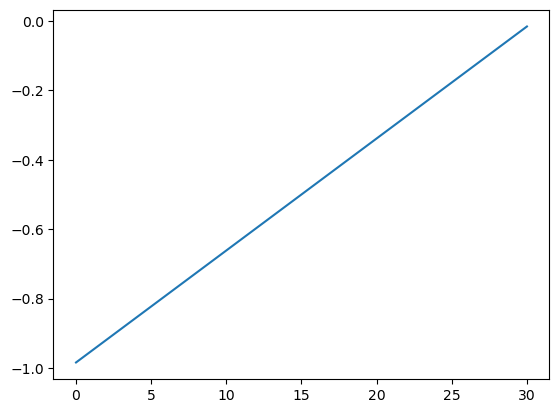

In [13]:
plt.plot(WAOM4.s_rho.values)

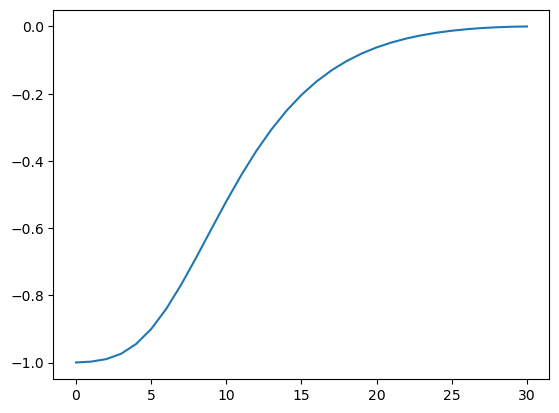

In [14]:
 plt.plot(WAOM4.Cs_r.values)

##### in case I want to calculate z_rho separately:

In [39]:
dx = xr.open_mfdataset(filelist)

# trying w/ original file:
hwater = dx.h - abs(dx.zice) 
    
# compute vertical transformation functional
S_rho = (dx.hc * dx.s_rho + dx.Cs_r * hwater) / (dx.hc + hwater)
# compute depth of rho (layers) and w (interfaces) points
z_rho = WAOM4.zeta + (WAOM4.zeta + hwater) * S_rho 


In [40]:
z_rho

<xarray.DataArray (time: 12, yh: 1398, xh: 1573, eta_rho: 1400, xi_rho: 1575,
                   s_rho: 31)> Size: 14PB
dask.array<add, shape=(12, 1398, 1573, 1400, 1575, 31), dtype=float64, chunksize=(1, 1398, 1573, 1400, 1575, 31), chunktype=numpy.ndarray>
Coordinates:
    Vtransform  int32 4B 2
    h           (yh, xh) float64 18MB dask.array<chunksize=(1398, 1573), meta=np.ndarray>
    hc          float64 8B 250.0
    lat_rho     (yh, xh) float64 18MB dask.array<chunksize=(1398, 1573), meta=np.ndarray>
    lon_rho     (yh, xh) float64 18MB dask.array<chunksize=(1398, 1573), meta=np.ndarray>
  * time        (time) datetime64[ns] 96B 2026-01-13T12:00:00 ... 2026-12-16T...
    x_rho       (eta_rho, xi_rho) float64 18MB dask.array<chunksize=(1400, 1575), meta=np.ndarray>
    y_rho       (eta_rho, xi_rho) float64 18MB dask.array<chunksize=(1400, 1575), meta=np.ndarray>
  * s_rho       (s_rho) float64 248B -0.9839 -0.9516 ... -0.04839 -0.01613
Dimensions without coordinates: yh, xh, eta_rho, xi_rho

In [41]:
WAOM4['z_rho'] = z_rho
WAOM4['z_u'] = grid_waom4.interp(WAOM4['z_rho'], 'X', boundary='extend')
WAOM4['z_v'] = grid_waom4.interp(WAOM4['z_rho'], 'Y', boundary='fill')


##### doing a few plots of z_rho, depth to check:

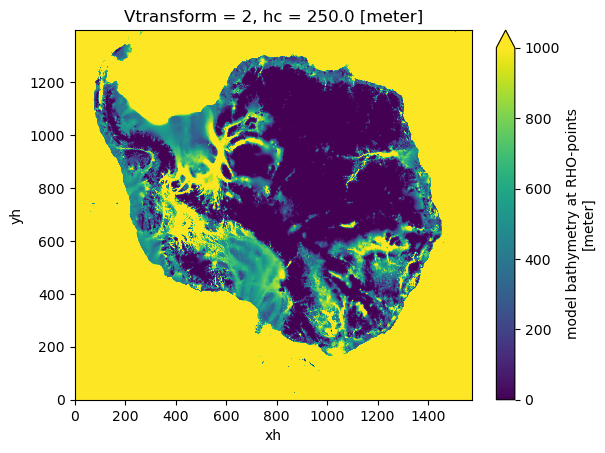

In [22]:
WAOM4.h.plot(vmin=0,vmax=1000)

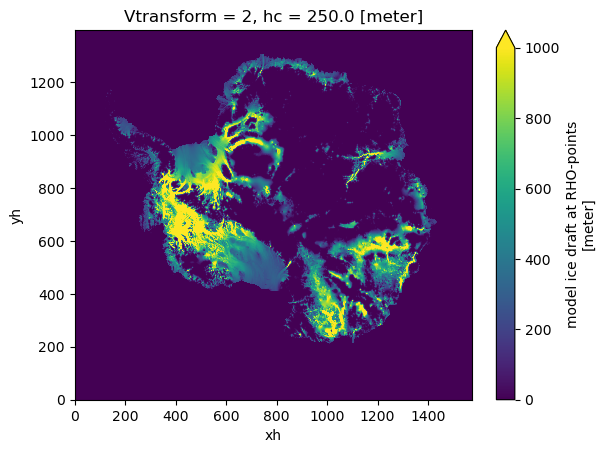

In [23]:
abs(WAOM4.zice).plot(vmin=0,vmax=1000)

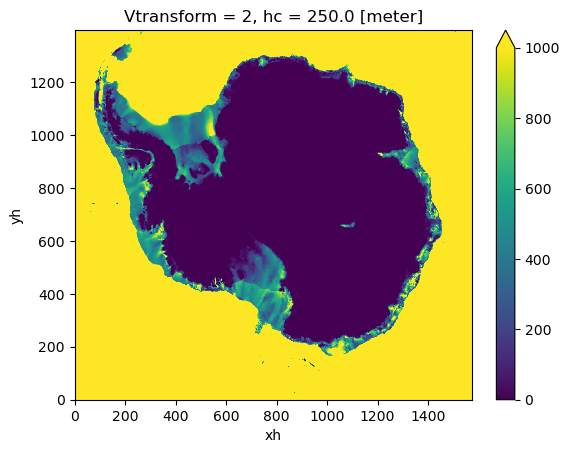

In [27]:
hwater = WAOM4.h - abs(WAOM4.zice) 

hwater.plot(vmin=0,vmax=1000)

##### plotting layer thickness:

In [61]:
WAOM4

<xarray.Dataset> Size: 51GB
Dimensions:     (s_rho: 31, s_w: 32, time: 12, yh: 1398, xh: 1573, xq: 1574,
                 yq: 1399)
Coordinates: (12/16)
    Cs_r        (s_rho) float64 248B dask.array<chunksize=(31,), meta=np.ndarray>
    Cs_w        (s_w) float64 256B dask.array<chunksize=(32,), meta=np.ndarray>
    Vtransform  int32 4B ...
    h           (yh, xh) float64 18MB dask.array<chunksize=(1398, 1573), meta=np.ndarray>
    hc          float64 8B ...
    lat_psi     (yq, xq) float64 18MB dask.array<chunksize=(1399, 1574), meta=np.ndarray>
    ...          ...
    lon_rho     (yh, xh) float64 18MB dask.array<chunksize=(1398, 1573), meta=np.ndarray>
    lon_u       (yh, xq) float64 18MB dask.array<chunksize=(1398, 1574), meta=np.ndarray>
    lon_v       (yq, xh) float64 18MB dask.array<chunksize=(1399, 1573), meta=np.ndarray>
  * time        (time) datetime64[ns] 96B 2026-01-13T12:00:00 ... 2026-12-16T...
  * s_rho       (s_rho) float64 248B -0.9839 -0.9516 ... -0.04839 -0.01613
  * s_w         (s_w) float64 256B -1.0 -0.9677 -0.9355 ... -0.03226 0.0
Dimensions without coordinates: yh, xh, xq, yq
Data variables: (12/35)
    Hbbl        (time, yh, xh) float32 106MB dask.array<chunksize=(1, 1398, 1573), meta=np.ndarray>
    Hsbl        (time, yh, xh) float32 106MB dask.array<chunksize=(1, 1398, 1573), meta=np.ndarray>
    Huon        (time, s_rho, yh, xq) float32 3GB dask.array<chunksize=(1, 31, 1398, 1574), meta=np.ndarray>
    Hvom        (time, s_rho, yq, xh) float32 3GB dask.array<chunksize=(1, 31, 1399, 1573), meta=np.ndarray>
    angle       (yh, xh) float64 18MB dask.array<chunksize=(1398, 1573), meta=np.ndarray>
    dmde        (yh, xh) float64 18MB dask.array<chunksize=(1398, 1573), meta=np.ndarray>
    ...          ...
    zeta        (time, yh, xh) float32 106MB dask.array<chunksize=(1, 1398, 1573), meta=np.ndarray>
    zice        (yh, xh) float64 18MB dask.array<chunksize=(1398, 1573), meta=np.ndarray>
    z_rho       (time, s_rho, yh, xh) float64 7GB dask.array<chunksize=(1, 31, 1398, 1573), meta=np.ndarray>
    z_w         (time, s_w, yh, xh) float64 7GB dask.array<chunksize=(1, 32, 1398, 1573), meta=np.ndarray>
    z_u         (time, s_rho, yh, xq) float64 7GB dask.array<chunksize=(1, 31, 1398, 1574), meta=np.ndarray>
    z_v         (time, s_rho, yq, xh) float64 7GB dask.array<chunksize=(1, 31, 1399, 1573), meta=np.ndarray>
Attributes: (12/35)
    CPP_options:       WAOM4, ADD_FSOBC, ADD_M2OBC, ANA_BSFLUX, ANA_BTFLUX, A...
    Conventions:       CF-1.4
    NCO:               netCDF Operators version 5.0.5 (Homepage = http://nco....
    NLM_LBC:           \nEDGE:  WEST   SOUTH  EAST   NORTH  \nzeta:  Cha    C...
    ana_file:          ROMS/Functionals/ana_btflux.h, ROMS/Functionals/ana_sr...
    avg_base:          /scratch/gi0/fbd581/waom4extend_shflim_S_0.25Q/output_...
    ...                ...
    script_file:       
    svn_rev:           Unversioned directory
    svn_url:           https:://myroms.org/svn/src
    tiling:            028x024
    title:             Whole Antarctic and Ocean Application, 4 km resolution
    type:              ROMS/TOMS nonlinear model averages file

In [62]:
# %%time # takes time!
# z_rho.load()

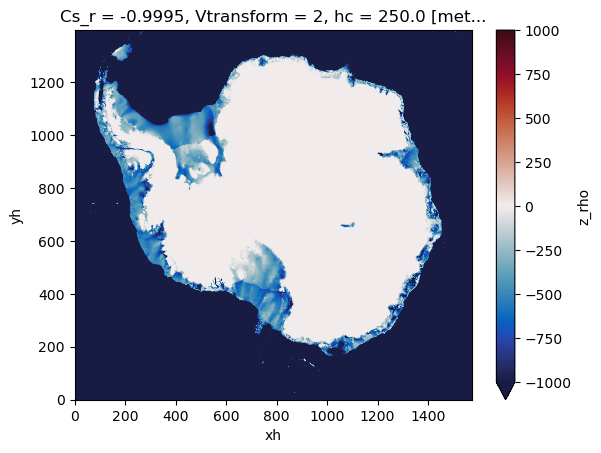

In [63]:
WAOM4.z_rho.isel(time=1,s_rho=0).plot(cmap='balance',vmin=-1000,vmax=1000) # here seems OK, depths are negative both deep ocean and cont. shelf

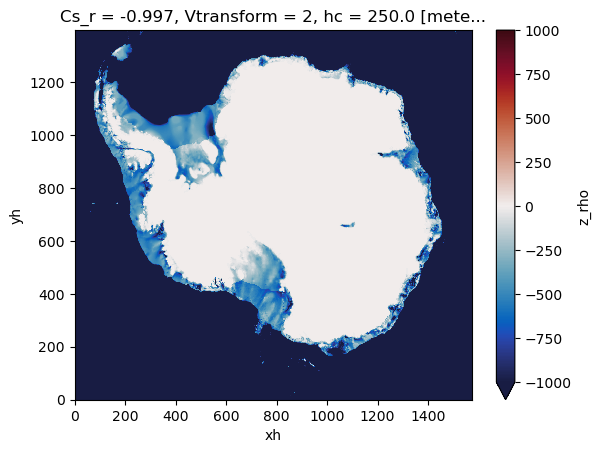

In [64]:
WAOM4.z_rho.isel(time=1,s_rho=1).plot(cmap='balance',vmin=-1000,vmax=1000)

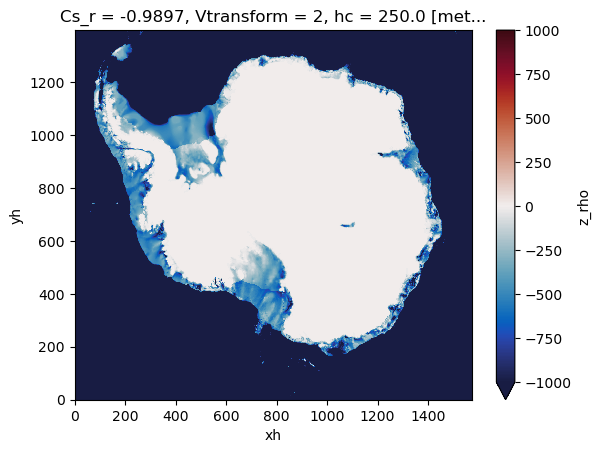

In [65]:
WAOM4.z_rho.isel(time=1,s_rho=2).plot(cmap='balance',vmin=-1000,vmax=1000)

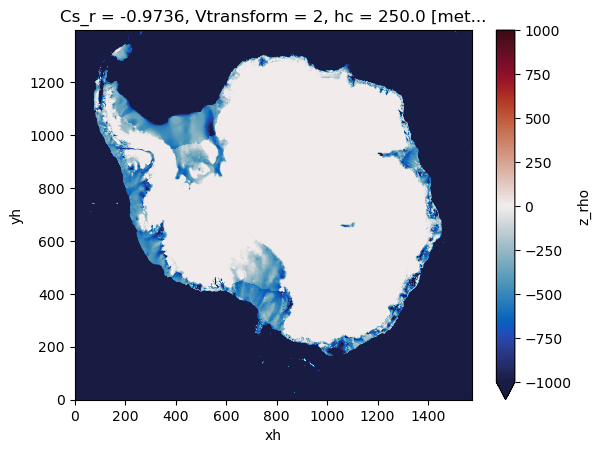

In [66]:
WAOM4.z_rho.isel(time=1,s_rho=3).plot(cmap='balance',vmin=-1000,vmax=1000)

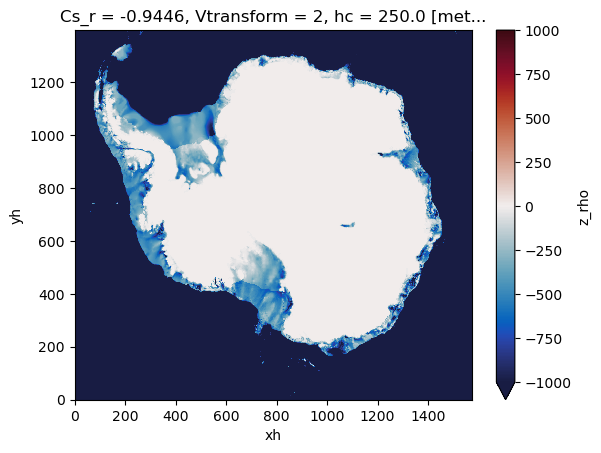

In [67]:
WAOM4.z_rho.isel(time=1,s_rho=4).plot(cmap='balance',vmin=-1000,vmax=1000)

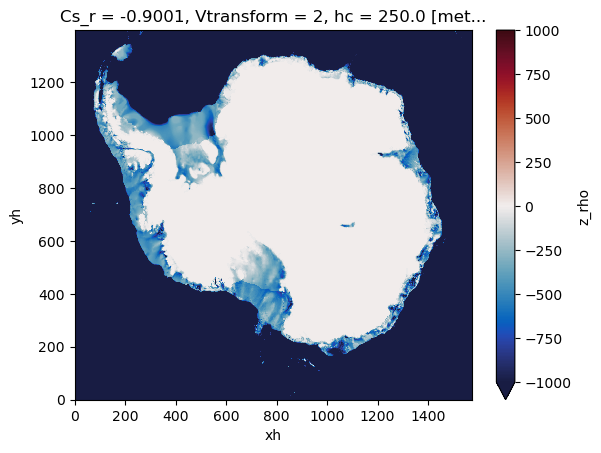

In [42]:
WAOM4.z_rho.isel(time=1,s_rho=5).plot(cmap='balance',vmin=-1000,vmax=1000)  # at layer 5, thickness at the cont. shelf start to become positive!!!

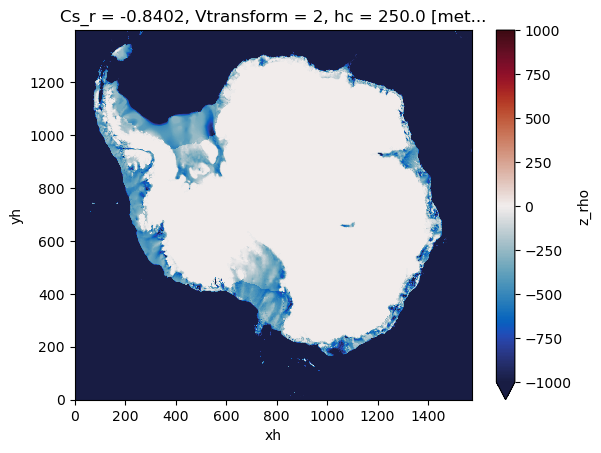

In [69]:
WAOM4.z_rho.isel(time=1,s_rho=6).plot(cmap='balance',vmin=-1000,vmax=1000)  # at layer 5, thickness at the cont. shelf start to become positive!!!

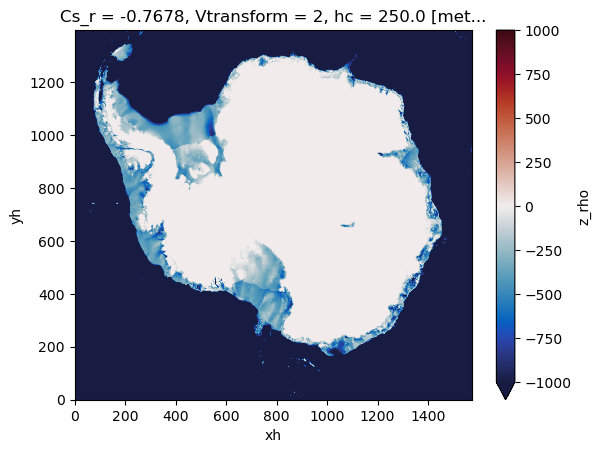

In [70]:
WAOM4.z_rho.isel(time=1,s_rho=7).plot(cmap='balance',vmin=-1000,vmax=1000)  # at layer 5, thickness at the cont. shelf start to become positive!!!

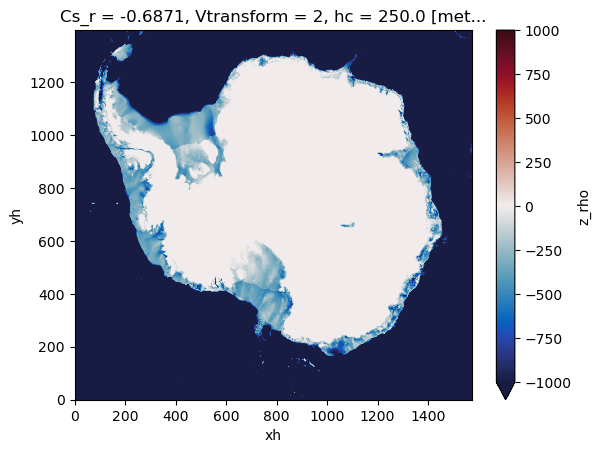

In [71]:
WAOM4.z_rho.isel(time=1,s_rho=8).plot(cmap='balance',vmin=-1000,vmax=1000)  # at layer 5, thickness at the cont. shelf start to become positive!!!

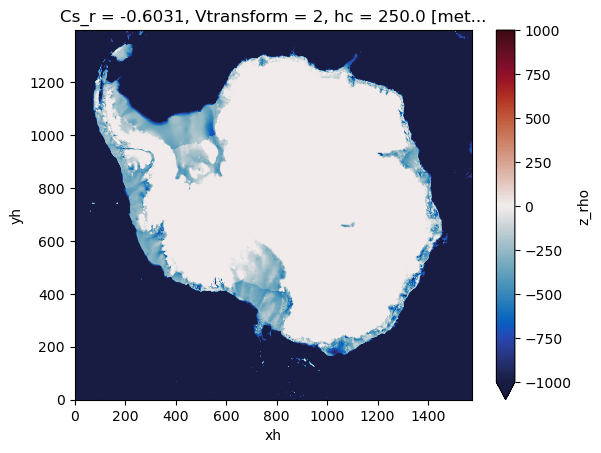

In [72]:
WAOM4.z_rho.isel(time=1,s_rho=9).plot(cmap='balance',vmin=-1000,vmax=1000)  # at layer 5, thickness at the cont. shelf start to become positive!!!

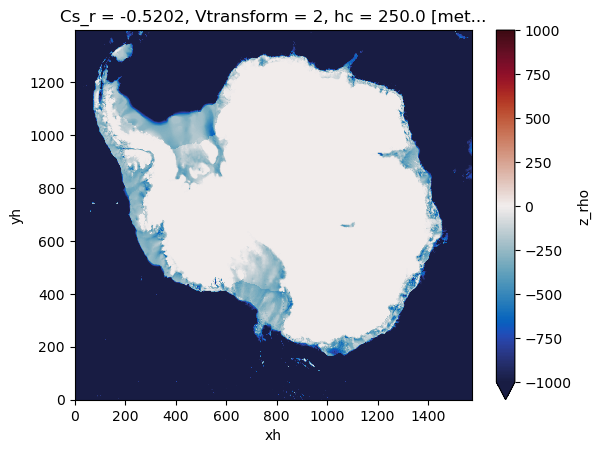

In [73]:
WAOM4.z_rho.isel(time=1,s_rho=10).plot(cmap='balance',vmin=-1000,vmax=1000) # at layer 10, shelf has ~1000m or so thickness, and deep ocean is close to zero???

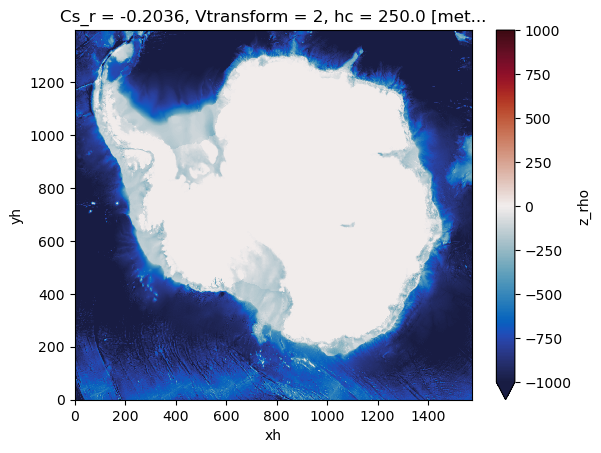

In [74]:
WAOM4.z_rho.isel(time=1,s_rho=15).plot(cmap='balance',vmin=-1000,vmax=1000)

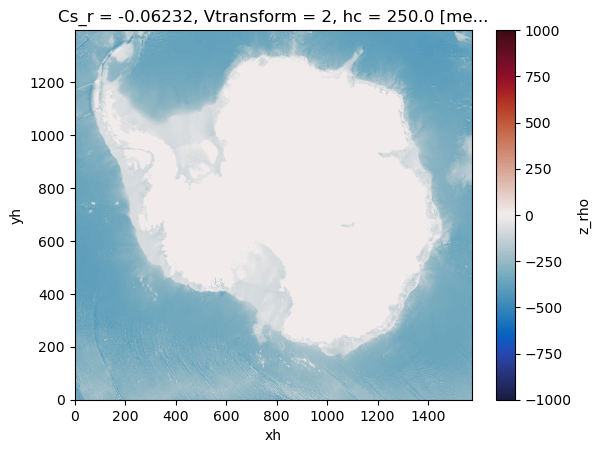

In [75]:
WAOM4.z_rho.isel(time=1,s_rho=20).plot(cmap='balance',vmin=-1000,vmax=1000)

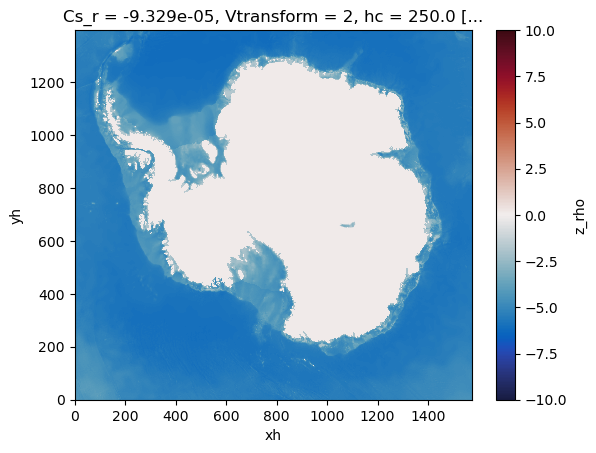

In [43]:
WAOM4.z_rho.isel(time=1,s_rho=30).plot(cmap='balance',vmin=-10,vmax=10)

In [29]:
WAOM4.z_rho.shape

(12, 31, 1398, 1573)

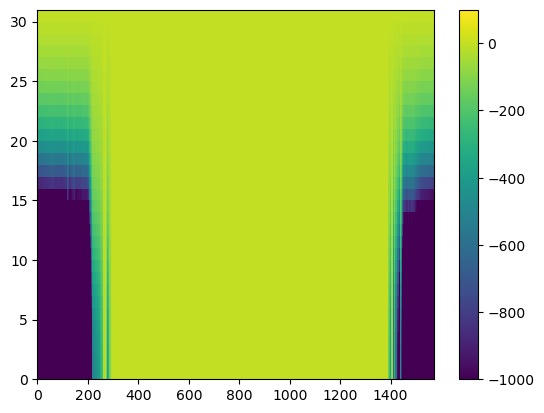

In [51]:
plt.pcolormesh(WAOM4.z_rho[0,:,700,:],vmin=-1000,vmax=100)
plt.colorbar()

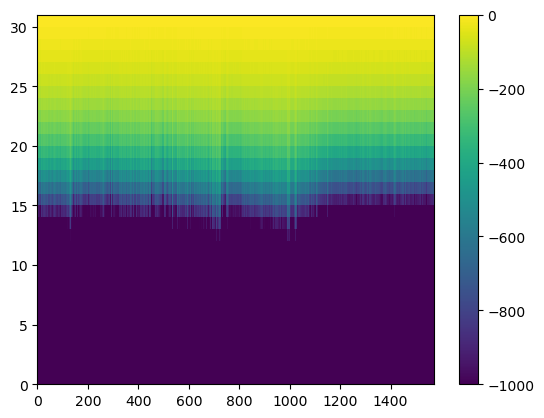

In [46]:
plt.pcolormesh(WAOM4.z_rho[0,:,100,:],vmin=-1000,vmax=0)
plt.colorbar()

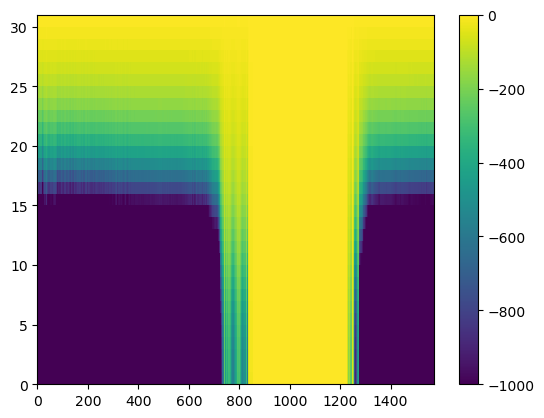

In [47]:
plt.pcolormesh(WAOM4.z_rho[0,:,300,:],vmin=-1000,vmax=0)
plt.colorbar()

In [59]:
WAOM4.z_rho[0,:,500,:].shape

(31, 1573)

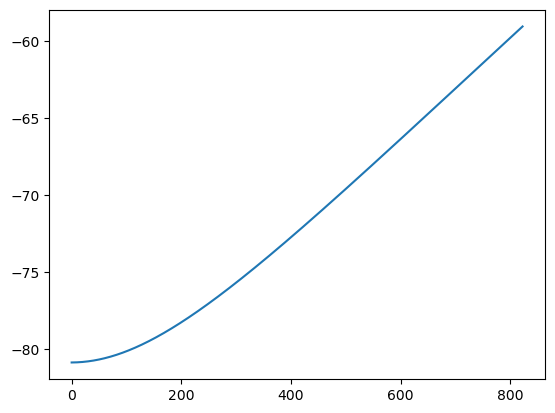

In [79]:
plt.plot(WAOM4.lat_rho[500,750:])

In [86]:
WAOM4.temp[0,:,750:,:].shape

(31, 648, 1573)

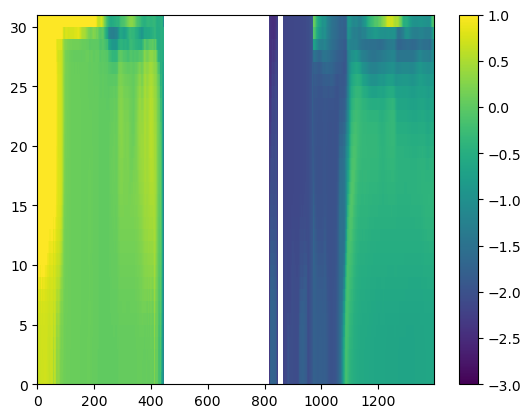

In [99]:
plt.pcolormesh(WAOM4.temp[0,:,:,465],vmin=-3,vmax=1)
plt.colorbar()
# plt.ylim(-1000,0)

(-800.0, 0.0)

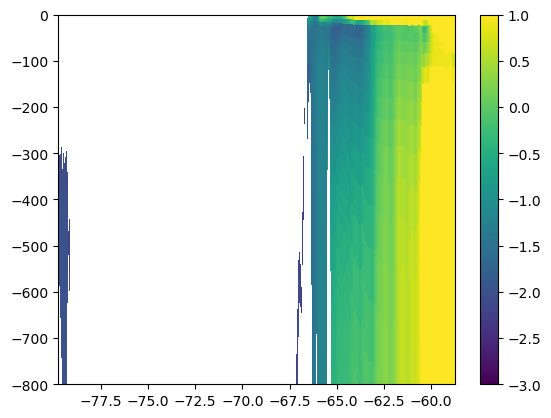

In [96]:
ii=470
plt.pcolormesh(WAOM4.lat_rho[ii,750:],WAOM4.z_rho[0,:,ii,750:]-abs(WAOM4.zice[ii,750:]),WAOM4.temp[0,:,ii,750:],vmin=-3,vmax=1)
plt.colorbar()
plt.ylim(-800,0)

(-800.0, 0.0)

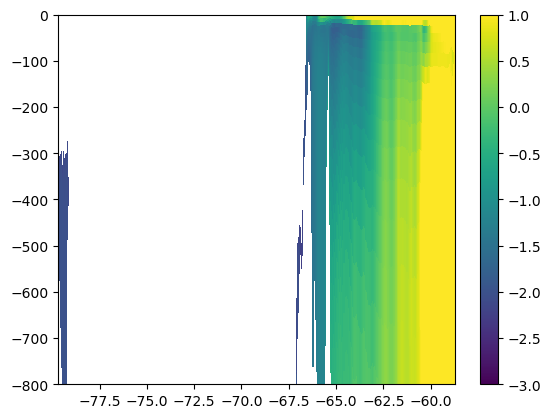

In [97]:
ii=468
plt.pcolormesh(WAOM4.lat_rho[ii,750:],WAOM4.z_rho[0,:,ii,750:]-abs(WAOM4.zice[ii,750:]),WAOM4.temp[0,:,ii,750:],vmin=-3,vmax=1)
plt.colorbar()
plt.ylim(-800,0)

<xarray.DataArray 'lon_rho' (xh: 823)> Size: 7kB
dask.array<getitem, shape=(823,), dtype=float64, chunksize=(823,), chunktype=numpy.ndarray>
Coordinates:
    Vtransform  int32 4B ...
    h           (xh) float64 7kB dask.array<chunksize=(823,), meta=np.ndarray>
    hc          float64 8B ...
    lat_rho     (xh) float64 7kB dask.array<chunksize=(823,), meta=np.ndarray>
    lon_rho     (xh) float64 7kB dask.array<chunksize=(823,), meta=np.ndarray>
Dimensions without coordinates: xh
Attributes:
    long_name:      longitude of RHO-points
    standard_name:  longitude
    units:          degree_east


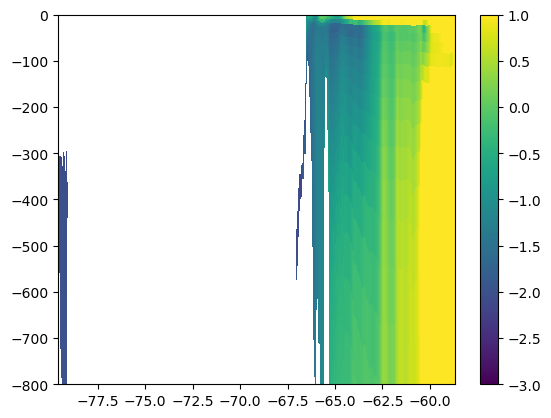

In [100]:
ii=465
plt.pcolormesh(WAOM4.lat_rho[ii,750:],WAOM4.z_rho[0,:,ii,750:]-abs(WAOM4.zice[ii,750:]),WAOM4.temp[0,:,ii,750:],vmin=-3,vmax=1)
plt.colorbar()
plt.ylim(-800,0)
print(WAOM4.lon_rho[ii,750:])

<xarray.DataArray 'lon_rho' (xh: 823)> Size: 7kB
dask.array<getitem, shape=(823,), dtype=float64, chunksize=(823,), chunktype=numpy.ndarray>
Coordinates:
    Vtransform  int32 4B ...
    h           (xh) float64 7kB dask.array<chunksize=(823,), meta=np.ndarray>
    hc          float64 8B ...
    lat_rho     (xh) float64 7kB dask.array<chunksize=(823,), meta=np.ndarray>
    lon_rho     (xh) float64 7kB dask.array<chunksize=(823,), meta=np.ndarray>
Dimensions without coordinates: xh
Attributes:
    long_name:      longitude of RHO-points
    standard_name:  longitude
    units:          degree_east


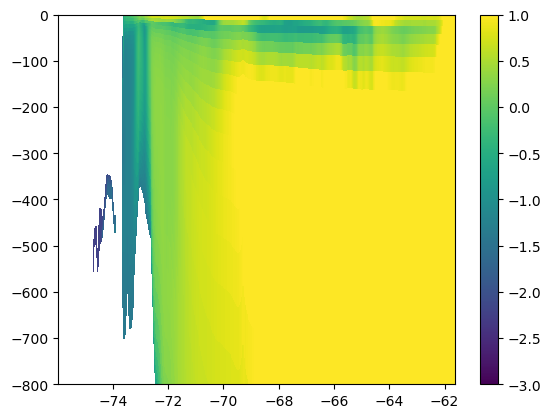

In [101]:
ii=510
plt.pcolormesh(WAOM4.lat_rho[ii,:450],WAOM4.z_rho[0,:,ii,:450]-abs(WAOM4.zice[ii,:450]),WAOM4.temp[0,:,ii,:450],vmin=-3,vmax=1)
plt.colorbar()
plt.ylim(-800,0)
print(WAOM4.lon_rho[ii,750:])

<xarray.DataArray 'lon_rho' (xh: 823)> Size: 7kB
dask.array<getitem, shape=(823,), dtype=float64, chunksize=(823,), chunktype=numpy.ndarray>
Coordinates:
    Vtransform  int32 4B ...
    h           (xh) float64 7kB dask.array<chunksize=(823,), meta=np.ndarray>
    hc          float64 8B ...
    lat_rho     (xh) float64 7kB dask.array<chunksize=(823,), meta=np.ndarray>
    lon_rho     (xh) float64 7kB dask.array<chunksize=(823,), meta=np.ndarray>
Dimensions without coordinates: xh
Attributes:
    long_name:      longitude of RHO-points
    standard_name:  longitude
    units:          degree_east


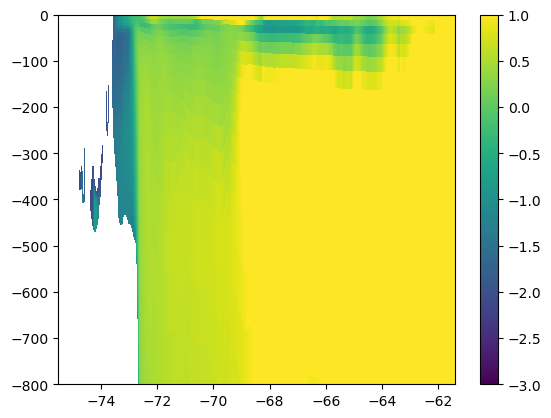

In [103]:
ii=490
plt.pcolormesh(WAOM4.lat_rho[ii,:450],WAOM4.z_rho[0,:,ii,:450]-abs(WAOM4.zice[ii,:450]),WAOM4.temp[0,:,ii,:450],vmin=-3,vmax=1)
plt.colorbar()
plt.ylim(-800,0)
print(WAOM4.lon_rho[ii,750:])

<xarray.DataArray 'lon_rho' (xh: 823)> Size: 7kB
dask.array<getitem, shape=(823,), dtype=float64, chunksize=(823,), chunktype=numpy.ndarray>
Coordinates:
    Vtransform  int32 4B ...
    h           (xh) float64 7kB dask.array<chunksize=(823,), meta=np.ndarray>
    hc          float64 8B ...
    lat_rho     (xh) float64 7kB dask.array<chunksize=(823,), meta=np.ndarray>
    lon_rho     (xh) float64 7kB dask.array<chunksize=(823,), meta=np.ndarray>
Dimensions without coordinates: xh
Attributes:
    long_name:      longitude of RHO-points
    standard_name:  longitude
    units:          degree_east


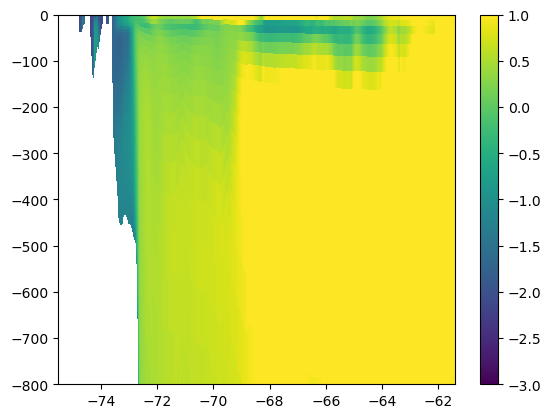

In [104]:
ii=490
plt.pcolormesh(WAOM4.lat_rho[ii,:450],WAOM4.z_rho[0,:,ii,:450],WAOM4.temp[0,:,ii,:450],vmin=-3,vmax=1)
plt.colorbar()
plt.ylim(-800,0)
print(WAOM4.lon_rho[ii,750:])

##### back...

In [116]:
grid_waom4

<xgcm.Grid>
X Axis (not periodic, boundary=None):
  * center   xh --> outer
  * outer    xq --> center
Y Axis (not periodic, boundary=None):
  * center   yh --> outer
  * outer    yq --> center
Z Axis (not periodic, boundary=None):
  * center   s_rho --> outer
  * outer    s_w --> center

In [112]:
store_name

'/g/data/gv90/fbd581/ROMS/OUTPUT/waom4extend_shflim_S_0.25Q/output_01-20yr/WAOM4_store_yr10'

#### WAOM4

In [120]:

WAOM4 = xr.open_zarr(store_name, consolidated=True)

# Create xgcm grid object
grid_waom4 = Grid(WAOM4, coords={'X': {'center': 'xh', 'outer': 'xq'},
                               'Y': {'center': 'yh', 'outer': 'yq'},
                               'Z': {'center': 's_rho', 'outer': 's_w'}},
                 periodic=False)

# Add depths of layers and interfaces to dataset
WAOM4 = compute_depth_layers(WAOM4, grid_waom4)



<xarray.DataArray 'z_u' (time: 12, s_rho: 31, yh: 1398, xq: 1574)> Size: 7GB
dask.array<transpose, shape=(12, 31, 1398, 1574), dtype=float64, chunksize=(1, 31, 1398, 1574), chunktype=numpy.ndarray>
Coordinates:
    Cs_r        (s_rho) float64 248B dask.array<chunksize=(31,), meta=np.ndarray>
    Vtransform  int32 4B ...
    hc          float64 8B ...
    lat_u       (yh, xq) float64 18MB dask.array<chunksize=(1398, 1574), meta=np.ndarray>
    lon_u       (yh, xq) float64 18MB dask.array<chunksize=(1398, 1574), meta=np.ndarray>
  * time        (time) datetime64[ns] 96B 2016-01-14T05:00:00 ... 2016-12-13T...
Dimensions without coordinates: s_rho, yh, xq
<xarray.DataArray 'z_v' (time: 12, s_rho: 31, yq: 1399, xh: 1573)> Size: 7GB
dask.array<transpose, shape=(12, 31, 1399, 1573), dtype=float64, chunksize=(1, 31, 1399, 1573), chunktype=numpy.ndarray>
Coordinates:
    Cs_r        (s_rho) float64 248B dask.array<chunksize=(31,), meta=np.ndarray>
    Vtransform  int32 4B ...
    hc          fl

#### WAOM10

In [16]:

WAOM10 = xr.open_zarr(store_name, consolidated=True)

# Create xgcm grid object
grid_waom10 = Grid(WAOM10, coords={'X': {'center': 'xh', 'outer': 'xq'},
                               'Y': {'center': 'yh', 'outer': 'yq'},
                               'Z': {'center': 's_rho', 'outer': 's_w'}},
                 periodic=False)

# Add depths of layers and interfaces to dataset
WAOM10 = compute_depth_layers(WAOM10, grid_waom10)



DEBUG!
<xarray.DataArray 'z_rho' (time: 12, s_rho: 31, yh: 558, xh: 628)>
dask.array<where, shape=(12, 31, 558, 628), dtype=float64, chunksize=(1, 31, 558, 628), chunktype=numpy.ndarray>
Coordinates:
    Cs_r        (s_rho) float64 dask.array<chunksize=(31,), meta=np.ndarray>
    Vtransform  int32 ...
    h           (yh, xh) float64 dask.array<chunksize=(558, 628), meta=np.ndarray>
    hc          float64 ...
    lat_rho     (yh, xh) float64 dask.array<chunksize=(558, 628), meta=np.ndarray>
    lon_rho     (yh, xh) float64 dask.array<chunksize=(558, 628), meta=np.ndarray>
  * time        (time) datetime64[ns] 2007-01-16T05:00:00 ... 2007-12-16T19:0...
Dimensions without coordinates: s_rho, yh, xh
<xarray.DataArray 'z_u' (time: 12, s_rho: 31, yh: 558, xq: 629)>
dask.array<transpose, shape=(12, 31, 558, 629), dtype=float64, chunksize=(1, 31, 558, 629), chunktype=numpy.ndarray>
Coordinates:
    Cs_r        (s_rho) float64 dask.array<chunksize=(31,), meta=np.ndarray>
    Vtransform  int32

### some plots to test:

In [13]:
WAOM4['v']

<xarray.DataArray 'v' (time: 12, s_rho: 31, yq: 1399, xh: 1573)> Size: 3GB
dask.array<open_dataset-v, shape=(12, 31, 1399, 1573), dtype=float32, chunksize=(1, 31, 1399, 1573), chunktype=numpy.ndarray>
Coordinates:
    Cs_r        (s_rho) float64 248B dask.array<chunksize=(31,), meta=np.ndarray>
    Vtransform  int32 4B ...
    hc          float64 8B ...
    lat_v       (yq, xh) float64 18MB dask.array<chunksize=(1399, 1573), meta=np.ndarray>
    lon_v       (yq, xh) float64 18MB dask.array<chunksize=(1399, 1573), meta=np.ndarray>
  * time        (time) datetime64[ns] 96B 2016-01-14T05:00:00 ... 2016-12-13T...
Dimensions without coordinates: s_rho, yq, xh
Attributes:
    field:      v-velocity, scalar, series
    long_name:  time-averaged v-momentum component
    time:       ocean_time
    units:      meter second-1

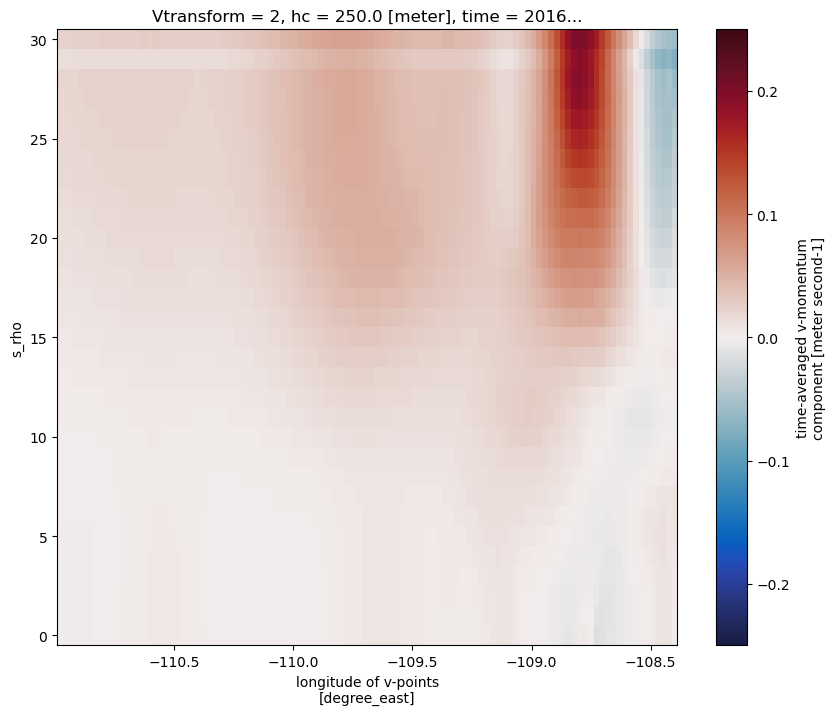

In [14]:


plt.figure(figsize=[10,8])

WAOM4['v'].isel(time=11, yq=500, xh=slice(0,100)).plot(x='lon_v', y='s_rho',
                                     vmin=-0.25, vmax=0.25,
                                     cmap=cmocean.cm.balance,
                                     subplot_kws={'facecolor': 'grey'})

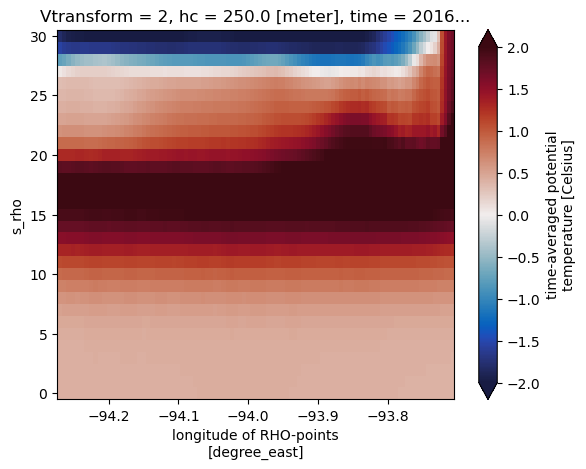

In [15]:
WAOM4['temp'].isel(time=7, yh=700, xh=slice(0,100)).plot(x='lon_rho', y='s_rho',
                                     vmin=-2, vmax=2,
                                     cmap=cmocean.cm.balance,
                                     subplot_kws={'facecolor': 'grey'})

In [16]:
WAOM4['temp'].isel(time=7, yh=500, xh=slice(0,100))

<xarray.DataArray 'temp' (s_rho: 31, xh: 100)> Size: 12kB
dask.array<getitem, shape=(31, 100), dtype=float32, chunksize=(31, 100), chunktype=numpy.ndarray>
Coordinates:
    Cs_r        (s_rho) float64 248B dask.array<chunksize=(31,), meta=np.ndarray>
    Vtransform  int32 4B ...
    h           (xh) float64 800B dask.array<chunksize=(100,), meta=np.ndarray>
    hc          float64 8B ...
    lat_rho     (xh) float64 800B dask.array<chunksize=(100,), meta=np.ndarray>
    lon_rho     (xh) float64 800B dask.array<chunksize=(100,), meta=np.ndarray>
    time        datetime64[ns] 8B 2016-08-14T03:00:00
Dimensions without coordinates: s_rho, xh
Attributes:
    field:      temperature, scalar, series
    long_name:  time-averaged potential temperature
    time:       ocean_time
    units:      Celsius

### plotting Dias et al (2025) paper Figure 1-style maps!

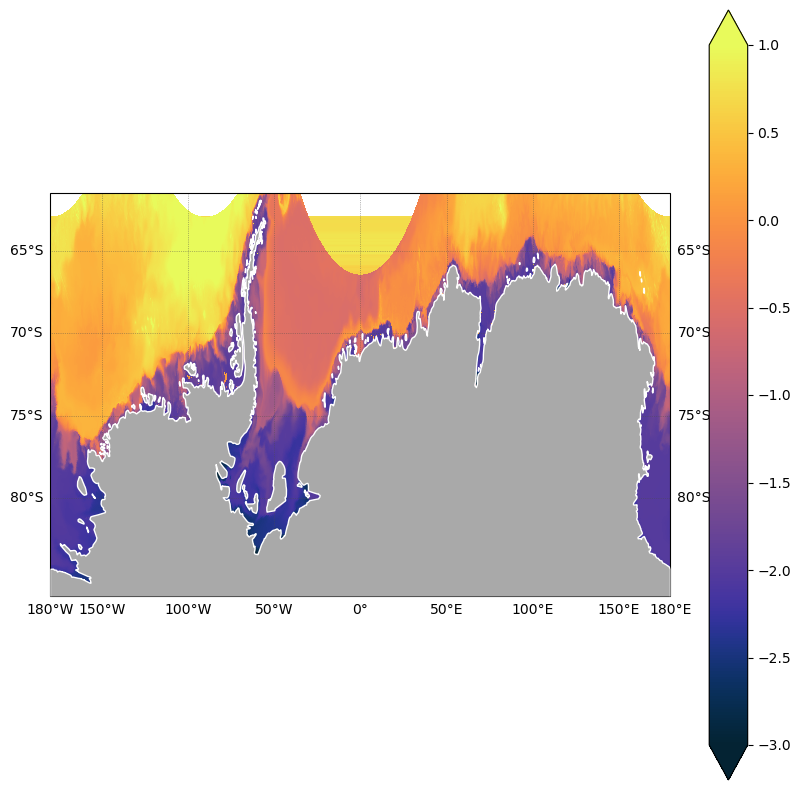

In [17]:
import matplotlib.ticker as mticker
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import cartopy.feature as cfeature

proj = ccrs.PlateCarree(central_longitude=0)

# extract temperature and depth for a given time
snapshot = WAOM4.isel(time=7)
temp_snapshot = snapshot['temp']
depth_snapshot = snapshot['z_rho']

# compute temperature at 100 meters depth using xgcm.transform
temp_300m = grid_waom4.transform(temp_snapshot, 'Z', np.array([300]),
                                target_data=depth_snapshot,
                                method='linear')

# plot results
plt.figure(figsize=[10,10])
ax = plt.axes(projection=proj)
p = temp_300m.plot(ax=ax, x='lon_rho', y='lat_rho',
                   vmin=-3, vmax=1,
                   cmap=cmocean.cm.thermal,
                   add_labels=False,
                   transform=ccrs.PlateCarree())

# background
# url = 'http://map1c.vis.earthdata.nasa.gov/wmts-geo/wmts.cgi'
# p.axes.add_wmts(url, 'BlueMarble_NextGeneration')
# p.axes.set_extent([225,255,20,50])

# p.axes.set_extent([-180,180,-65,-90])

gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,linewidth=.5, color=[.3,.3,.3], alpha=0.75, linestyle=':')
gl.xlines = True
gl.top_labels=False   # suppress top labels
gl.xlabels_bottom = True
gl.ylabels_left = False
gl.ylabels_right = True
gl.xlocator = mticker.FixedLocator([-180, -150, -100, -50, 0, 50, 100, 150, 180])
gl.ylocator = mticker.FixedLocator([-65, -70, -75, -80])
gl.xformatter = LONGITUDE_FORMATTER
gl.yformatter = LATITUDE_FORMATTER

ax.add_feature(cfeature.LAND, zorder=3, facecolor='darkgray',edgecolor='white')
ax.set_extent([-180, 180, -86, -61.5], crs=ccrs.PlateCarree())
x_left, x_right = ax.get_xlim()
y_low, y_high = ax.get_ylim()
ratio = .65  #.175

ax.set_aspect(abs((x_right-x_left)/(y_low-y_high))*ratio)

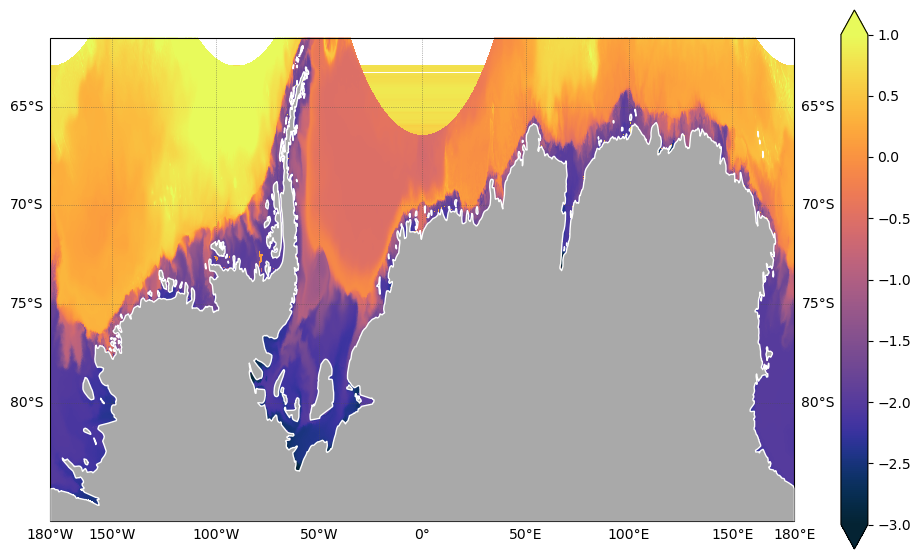

In [18]:
import matplotlib.ticker as mticker
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import cartopy.feature as cfeature

proj = ccrs.PlateCarree(central_longitude=0)

# extract temperature and depth for a given time
snapshot = WAOM4#.isel(time=7)
temp_snapshot = snapshot['temp'].mean('time')
depth_snapshot = snapshot['z_rho'].mean('time')

# compute temperature at 100 meters depth using xgcm.transform
temp_500m = grid_waom4.transform(temp_snapshot, 'Z', np.array([500]),
                                target_data=depth_snapshot,
                                method='linear')

# plot results
plt.figure(figsize=[12,7])
ax = plt.axes(projection=proj)
p = temp_500m.plot(ax=ax, x='lon_rho', y='lat_rho',
                   vmin=-3, vmax=1,
                   cmap=cmocean.cm.thermal,
                   add_labels=False,
                   transform=ccrs.PlateCarree())

# background
# url = 'http://map1c.vis.earthdata.nasa.gov/wmts-geo/wmts.cgi'
# p.axes.add_wmts(url, 'BlueMarble_NextGeneration')
# p.axes.set_extent([225,255,20,50])

# p.axes.set_extent([-180,180,-65,-90])

gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,linewidth=.5, color=[.3,.3,.3], alpha=0.75, linestyle=':')
gl.xlines = True
gl.top_labels=False   # suppress top labels
# gl.xlabels_bottom = True
# gl.ylabels_left = False
# gl.ylabels_right = True
gl.xlocator = mticker.FixedLocator([-180, -150, -100, -50, 0, 50, 100, 150, 180])
gl.ylocator = mticker.FixedLocator([-65, -70, -75, -80])
gl.xformatter = LONGITUDE_FORMATTER
gl.yformatter = LATITUDE_FORMATTER

ax.add_feature(cfeature.LAND, zorder=3, facecolor='darkgray',edgecolor='white')
ax.set_extent([-180, 180, -86, -61.5], crs=ccrs.PlateCarree())
x_left, x_right = ax.get_xlim()
y_low, y_high = ax.get_ylim()
ratio = .65  #.175

ax.set_aspect(abs((x_right-x_left)/(y_low-y_high))*ratio)

In [ ]:
### Investigating diffs between depth-levels linearly interpolated:

The results seen a bit weird; although there's differences between trying different levels (0, 400, 800)

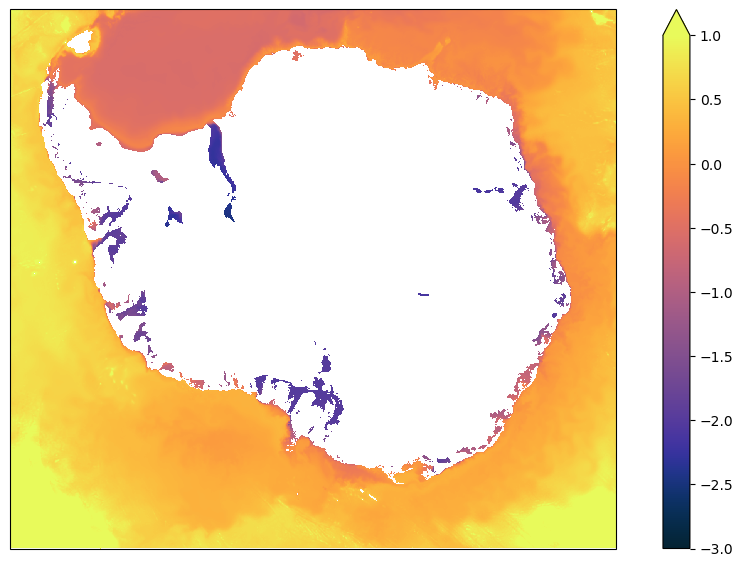

In [24]:

# extract temperature and depth for a given time
snapshot = WAOM4.isel(time=7)
temp_snapshot = snapshot['temp']#.mean('time')
depth_snapshot = snapshot['z_rho']#.mean('time')

# compute temperature at 100 meters depth using xgcm.transform
temp_400m = grid_waom4.transform(temp_snapshot, 'Z', np.array([-400]),
                                target_data=depth_snapshot,
                                method='linear')

# plot results
plt.figure(figsize=[12,7])
ax = plt.axes(projection=proj)
p = temp_400m.plot(ax=ax, x='lon_rho', y='lat_rho',
                   vmin=-3, vmax=1,
                   cmap=cmocean.cm.thermal,
                   add_labels=False,
                   transform=ccrs.PlateCarree())

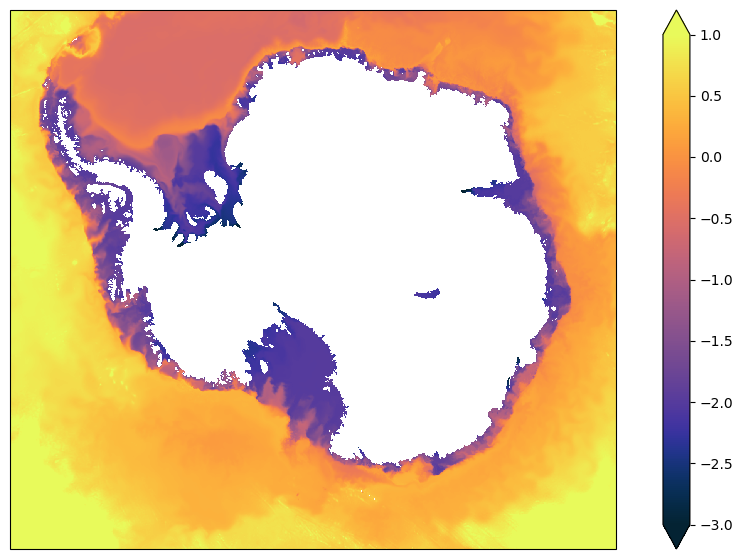

In [70]:
# SURFACEE
# extract temperature and depth for a given time
snapshot = WAOM4.isel(time=7)
temp_snapshot = snapshot['temp']#.mean('time')
depth_snapshot = snapshot['z_rho']#.mean('time')

# compute temperature at 100 meters depth using xgcm.transform
temp_0m = grid_waom4.transform(temp_snapshot, 'Z', np.array([0]),
                                target_data=depth_snapshot,
                                method='linear')

# plot results
proj = ccrs.SouthPolarStereo()
plt.figure(figsize=[12,7])
ax = plt.axes(projection=proj)
p = temp_0m.plot(ax=ax, x='lon_rho', y='lat_rho',
                   vmin=-3, vmax=1,
                   cmap=cmocean.cm.thermal,
                   add_labels=False,
                   transform=ccrs.PlateCarree())

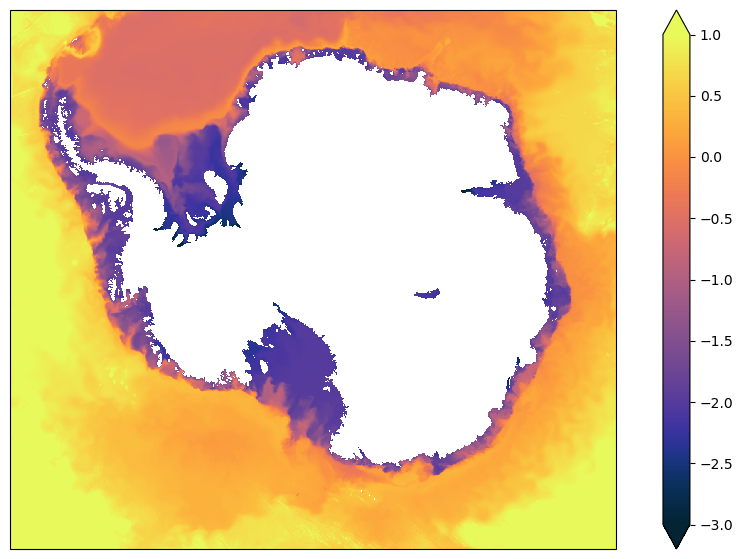

In [32]:
## 400M

# extract temperature and depth for a given time
snapshot = WAOM4.isel(time=7)
temp_snapshot = snapshot['temp']#.mean('time')
depth_snapshot = snapshot['z_rho']#.mean('time')

# compute temperature at 100 meters depth using xgcm.transform
temp_400m = grid_waom4.transform(temp_snapshot, 'Z', np.array([400]),
                                target_data=depth_snapshot,
                                method='linear')

temp_diff = temp_0m - temp_400m
# plot results
plt.figure(figsize=[12,7])
ax = plt.axes(projection=proj)
p = temp_400m.plot(ax=ax, x='lon_rho', y='lat_rho',
                   vmin=-3, vmax=1,
                   cmap=cmocean.cm.thermal,
                   add_labels=False,
                   transform=ccrs.PlateCarree())

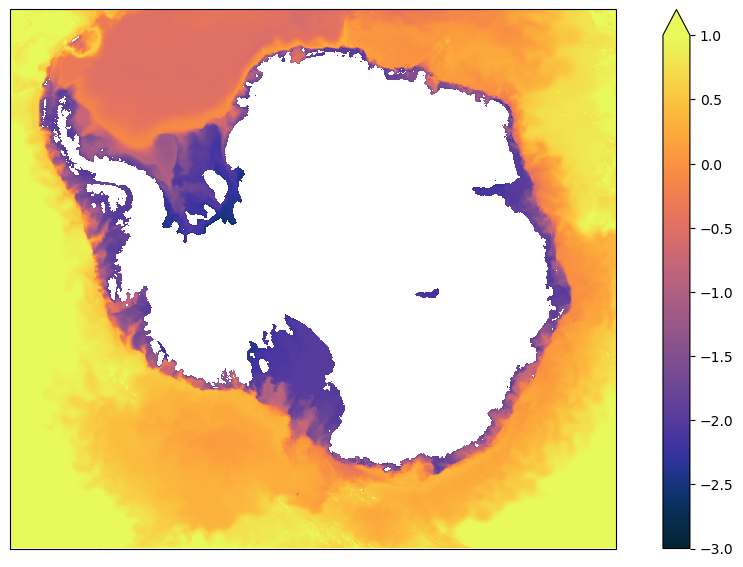

In [40]:
## 800M

# extract temperature and depth for a given time
snapshot = WAOM4.isel(time=7)
temp_snapshot = snapshot['temp']#.mean('time')
depth_snapshot = snapshot['z_rho']#.mean('time')

# compute temperature at 100 meters depth using xgcm.transform
temp_800m = grid_waom4.transform(temp_snapshot, 'Z', np.array([800]),
                                target_data=depth_snapshot,
                                method='linear')

# plot results
plt.figure(figsize=[12,7])
ax = plt.axes(projection=proj)
p = temp_800m.plot(ax=ax, x='lon_rho', y='lat_rho',
                   vmin=-3, vmax=1,
                   cmap=cmocean.cm.thermal,
                   add_labels=False,
                   transform=ccrs.PlateCarree())

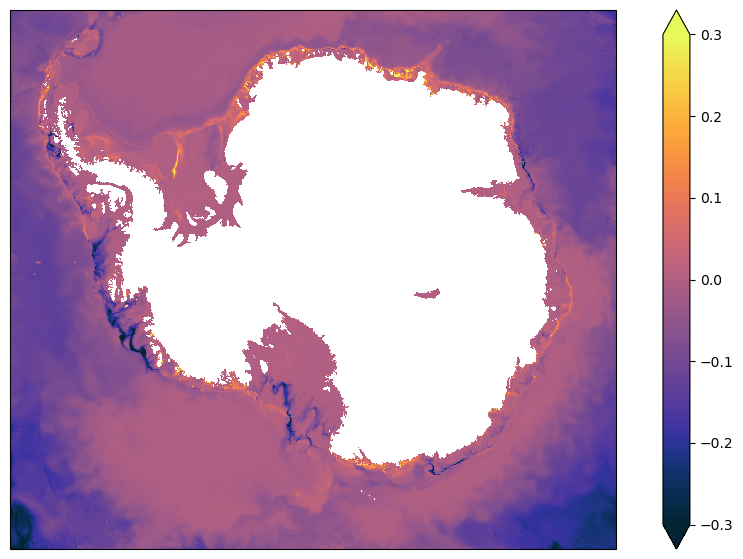

In [41]:
temp_diff1 = temp_0m.mean('z_rho') - temp_400m.mean('z_rho')
temp_diff2 = temp_0m.mean('z_rho') - temp_800m.mean('z_rho')

# plot results
plt.figure(figsize=[12,7])
ax = plt.axes(projection=proj)
p = temp_diff1.plot(ax=ax, x='lon_rho', y='lat_rho',
                   vmin=-.3, vmax=.3,
                   cmap=cmocean.cm.thermal,
                   add_labels=False,
                   transform=ccrs.PlateCarree())

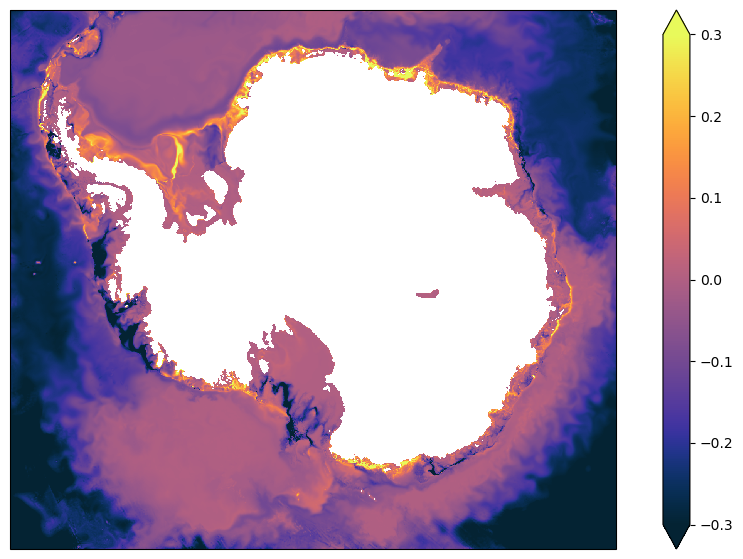

In [42]:
# plot results
plt.figure(figsize=[12,7])
ax = plt.axes(projection=proj)
p = temp_diff2.plot(ax=ax, x='lon_rho', y='lat_rho',
                   vmin=-.3, vmax=.3,
                   cmap=cmocean.cm.thermal,
                   add_labels=False,
                   transform=ccrs.PlateCarree())

In [43]:
# extract temperature and depth for a given time
snapshot = WAOM4.isel(time=7)
temp_snapshot = snapshot['temp']#.mean('time')
depth_snapshot = snapshot['z_rho']#.mean('time')

# compute temperature at 100 meters depth using xgcm.transform
# temp_400m = grid_waom4.transform(temp_snapshot, 'Z', np.array([400]),
#                                 target_data=depth_snapshot,
#                                 method='linear')

temp_400m = grid_waom4.transform(temp_snapshot, 'Z', np.array([400]),
                                target_data=depth_snapshot,
                                method='linear')

<xarray.DataArray 'temp' (s_rho: 31, yh: 1398, xh: 1573)> Size: 273MB
dask.array<getitem, shape=(31, 1398, 1573), dtype=float32, chunksize=(31, 1398, 1573), chunktype=numpy.ndarray>
Coordinates:
    Cs_r        (s_rho) float64 248B dask.array<chunksize=(31,), meta=np.ndarray>
    Vtransform  int32 4B ...
    h           (yh, xh) float64 18MB dask.array<chunksize=(1398, 1573), meta=np.ndarray>
    hc          float64 8B ...
    lat_rho     (yh, xh) float64 18MB dask.array<chunksize=(1398, 1573), meta=np.ndarray>
    lon_rho     (yh, xh) float64 18MB dask.array<chunksize=(1398, 1573), meta=np.ndarray>
    time        datetime64[ns] 8B 2016-08-14T03:00:00
Dimensions without coordinates: s_rho, yh, xh
Attributes:
    field:      temperature, scalar, series
    long_name:  time-averaged potential temperature
    time:       ocean_time
    units:      Celsius

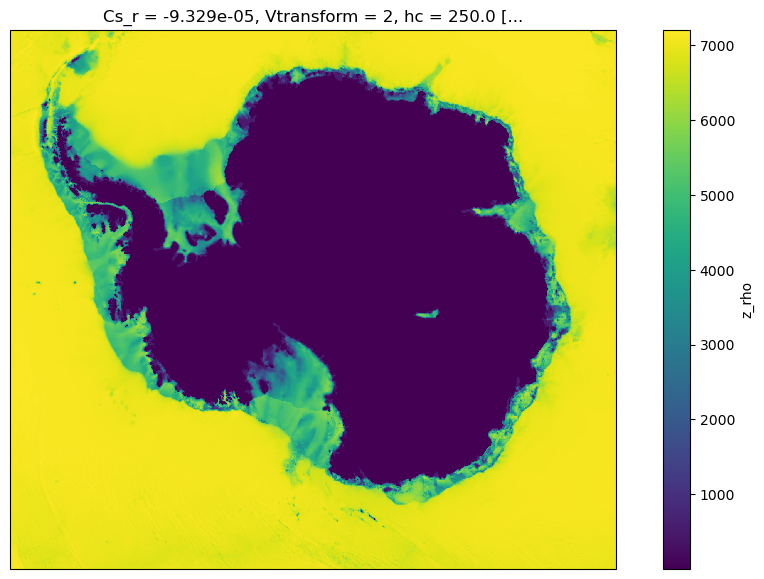

In [51]:
# plot results
plt.figure(figsize=[12,7])
ax = plt.axes(projection=proj)
p = depth_snapshot.isel(s_rho=-1).plot()

# depth_snapshot

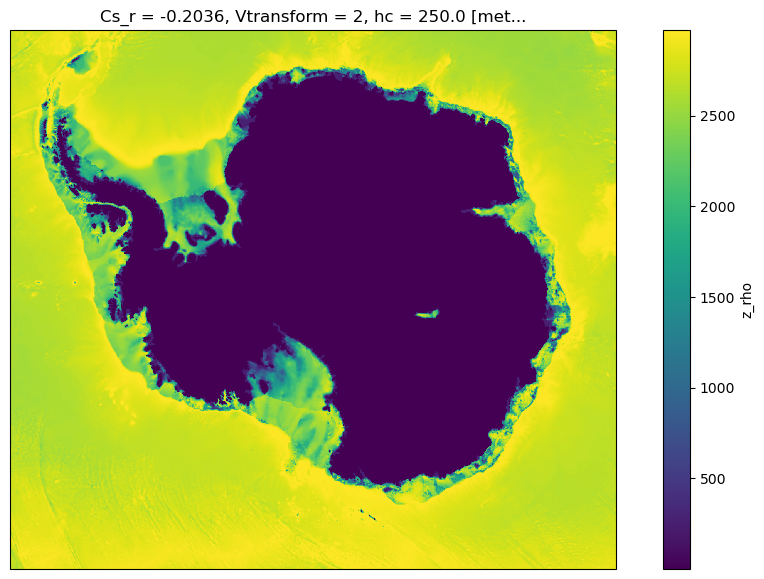

In [52]:
# plot results
plt.figure(figsize=[12,7])
ax = plt.axes(projection=proj)
p = depth_snapshot.isel(s_rho=15).plot()

# depth_snapshot

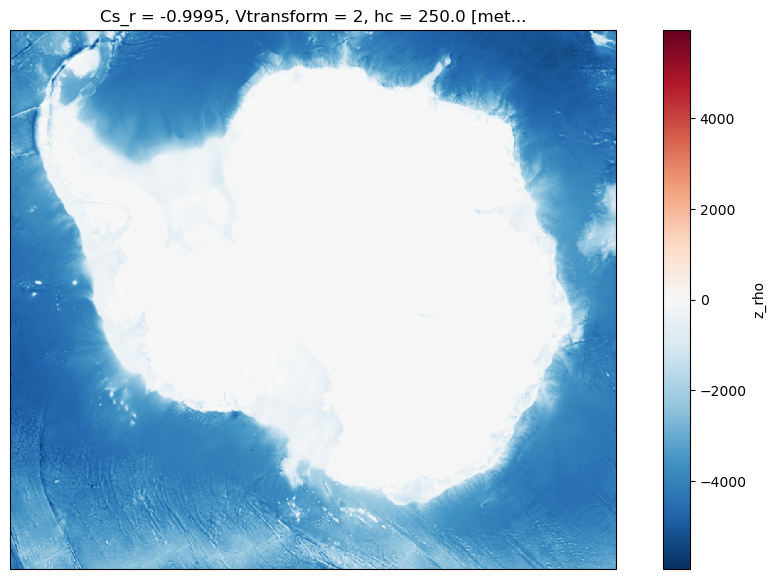

In [53]:
# plot results
plt.figure(figsize=[12,7])
ax = plt.axes(projection=proj)
p = depth_snapshot.isel(s_rho=0).plot()

# depth_snapshot

In [ ]:

# extract temperature and depth for a given time
snapshot = WAOM4.isel(time=7)
temp_tst = snapshot['temp']#.mean('time')
depth_snapshot = snapshot['z_rho']#.mean('time')

# compute temperature at 100 meters depth using xgcm.transform
temp_500m = grid_waom4.transform(temp_snapshot, 'Z', np.array([0]),
                                target_data=depth_snapshot,
                                method='linear')

# plot results
plt.figure(figsize=[12,7])
ax = plt.axes(projection=proj)
p = temp_500m.plot(ax=ax, x='lon_rho', y='lat_rho',
                   vmin=-3, vmax=1,
                   cmap=cmocean.cm.thermal,
                   add_labels=False,
                   transform=ccrs.PlateCarree())

### Totten region

/g/data/hh5/public/apps/miniconda3/envs/analysis3-23.04/lib/python3.9/site-packages/xgcm/grid.py:989: FutureWarning: From version 0.8.0 the Axis computation methods will be removed, in favour of using the Grid computation methods instead. i.e. use `Grid.transform` instead of `Axis.transform`
  warnings.warn(
/g/data/hh5/public/apps/miniconda3/envs/analysis3-23.04/lib/python3.9/site-packages/cartopy/mpl/gridliner.py:463: UserWarning: The .xlabels_bottom attribute is deprecated. Please use .bottom_labels to toggle visibility instead.
  warnings.warn('The .xlabels_bottom attribute is deprecated. Please '
/g/data/hh5/public/apps/miniconda3/envs/analysis3-23.04/lib/python3.9/site-packages/cartopy/mpl/gridliner.py:475: UserWarning: The .ylabels_left attribute is deprecated. Please use .left_labels to toggle visibility instead.
  warnings.warn('The .ylabels_left attribute is deprecated. Please '
/g/data/hh5/public/apps/miniconda3/envs/analysis3-23.04/lib/python3.9/site-packages/cartopy/mpl/gr

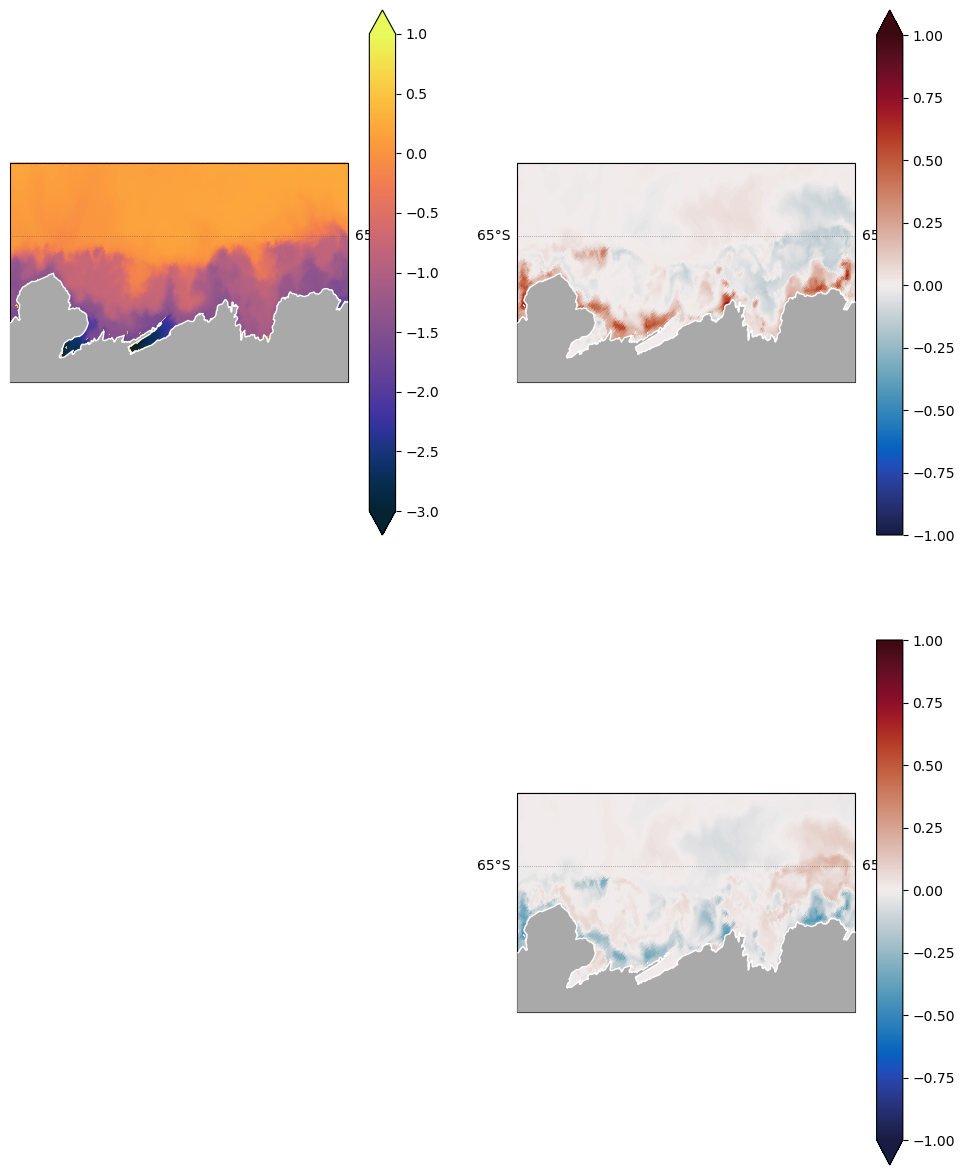

In [75]:
proj = ccrs.PlateCarree(central_longitude=0)

# extract temperature and depth for a given time
snapshot = WAOM4
temp_snapshot = snapshot['temp'].mean('time')
depth_snapshot = snapshot['z_rho'].mean('time')

# compute temperature at 100 meters depth using xgcm.transform
temp_500m_ANN = grid_waom4.transform(temp_snapshot, 'Z', np.array([200]),
                                target_data=depth_snapshot,
                                method='linear')

# plot results
fig = plt.figure(figsize=[12,15])
# ax = plt.axes(projection=proj)
ax = fig.add_subplot(2,2,1, projection=proj)
p = temp_500m_ANN.plot(ax=ax, x='lon_rho', y='lat_rho',
                   vmin=-3, vmax=1,
                   cmap=cmocean.cm.thermal,
                   add_labels=False,
                   transform=ccrs.PlateCarree())


gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,linewidth=.5, color=[.3,.3,.3], alpha=0.75, linestyle=':')
gl.xlines = True
gl.top_labels=False   # suppress top labels
gl.xlabels_bottom = True
gl.ylabels_left = False
gl.ylabels_right = True
gl.xlocator = mticker.FixedLocator([-180, -150, -100, -50, 0, 50, 100, 150, 180])
gl.ylocator = mticker.FixedLocator([-65, -70, -75, -80])
gl.xformatter = LONGITUDE_FORMATTER
gl.yformatter = LATITUDE_FORMATTER

ax.add_feature(cfeature.LAND, zorder=3, facecolor='darkgray',edgecolor='white')
ax.set_extent([110, 135, -68, -63.5], crs=ccrs.PlateCarree())
x_left, x_right = ax.get_xlim()
y_low, y_high = ax.get_ylim()
ratio = .65  #.175

ax.set_aspect(abs((x_right-x_left)/(y_low-y_high))*ratio)


## --- 2ND panel: summer anomaly

# extract temperature and depth for a given time
snapshot = WAOM4.isel(time=slice(0,4))
temp_snapshot = snapshot['temp'].mean('time')
depth_snapshot = snapshot['z_rho'].mean('time')

# compute temperature at 100 meters depth using xgcm.transform
temp_500m_SUM = grid_waom4.transform(temp_snapshot, 'Z', np.array([200]),
                                target_data=depth_snapshot,
                                method='linear')
temp_SUM_anom = (temp_500m_SUM+273.15) - (temp_500m_ANN+273.15)

ax = fig.add_subplot(2,2,2, projection=proj)
p = temp_SUM_anom.plot(ax=ax, x='lon_rho', y='lat_rho',
                   vmin=-1, vmax=1,
                   cmap=cmocean.cm.balance,
                   add_labels=False,
                   transform=ccrs.PlateCarree())


gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,linewidth=.5, color=[.3,.3,.3], alpha=0.75, linestyle=':')
gl.xlines = True
gl.top_labels=False   # suppress top labels
# gl.xlabels_bottom = True
# gl.ylabels_left = False
# gl.ylabels_right = True
gl.xlocator = mticker.FixedLocator([-180, -150, -100, -50, 0, 50, 100, 150, 180])
gl.ylocator = mticker.FixedLocator([-65, -70, -75, -80])
gl.xformatter = LONGITUDE_FORMATTER
gl.yformatter = LATITUDE_FORMATTER

ax.add_feature(cfeature.LAND, zorder=3, facecolor='darkgray',edgecolor='white')
ax.set_extent([110, 135, -68, -63.5], crs=ccrs.PlateCarree())
x_left, x_right = ax.get_xlim()
y_low, y_high = ax.get_ylim()
ratio = .65  #.175

ax.set_aspect(abs((x_right-x_left)/(y_low-y_high))*ratio)


## --- 2ND panel: winter anomaly

# extract temperature and depth for a given time
snapshot = WAOM4.isel(time=slice(5,9))
temp_snapshot = snapshot['temp'].mean('time')
depth_snapshot = snapshot['z_rho'].mean('time')

# compute temperature at 100 meters depth using xgcm.transform
temp_500m_WIN = grid_waom4.transform(temp_snapshot, 'Z', np.array([200]),
                                target_data=depth_snapshot,
                                method='linear')
temp_WIN_anom = (temp_500m_WIN+273.15) - (temp_500m_ANN+273.15)

ax = fig.add_subplot(2,2,4, projection=proj)
p = temp_WIN_anom.plot(ax=ax, x='lon_rho', y='lat_rho',
                   vmin=-1, vmax=1,
                   cmap=cmocean.cm.balance,
                   add_labels=False,
                   transform=ccrs.PlateCarree())


gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,linewidth=.5, color=[.3,.3,.3], alpha=0.75, linestyle=':')
gl.xlines = True
gl.top_labels=False   # suppress top labels
# gl.xlabels_bottom = True
# gl.ylabels_left = False
# gl.ylabels_right = True
gl.xlocator = mticker.FixedLocator([-180, -150, -100, -50, 0, 50, 100, 150, 180])
gl.ylocator = mticker.FixedLocator([-65, -70, -75, -80])
gl.xformatter = LONGITUDE_FORMATTER
gl.yformatter = LATITUDE_FORMATTER

ax.add_feature(cfeature.LAND, zorder=3, facecolor='darkgray',edgecolor='white')
ax.set_extent([110, 135, -68, -63.5], crs=ccrs.PlateCarree())
x_left, x_right = ax.get_xlim()
y_low, y_high = ax.get_ylim()
ratio = .65  #.175

ax.set_aspect(abs((x_right-x_left)/(y_low-y_high))*ratio)

### GETZ

/g/data/hh5/public/apps/miniconda3/envs/analysis3-23.04/lib/python3.9/site-packages/xgcm/grid.py:989: FutureWarning: From version 0.8.0 the Axis computation methods will be removed, in favour of using the Grid computation methods instead. i.e. use `Grid.transform` instead of `Axis.transform`
  warnings.warn(
/g/data/hh5/public/apps/miniconda3/envs/analysis3-23.04/lib/python3.9/site-packages/cartopy/mpl/gridliner.py:463: UserWarning: The .xlabels_bottom attribute is deprecated. Please use .bottom_labels to toggle visibility instead.
  warnings.warn('The .xlabels_bottom attribute is deprecated. Please '
/g/data/hh5/public/apps/miniconda3/envs/analysis3-23.04/lib/python3.9/site-packages/cartopy/mpl/gridliner.py:475: UserWarning: The .ylabels_left attribute is deprecated. Please use .left_labels to toggle visibility instead.
  warnings.warn('The .ylabels_left attribute is deprecated. Please '
/g/data/hh5/public/apps/miniconda3/envs/analysis3-23.04/lib/python3.9/site-packages/cartopy/mpl/gr

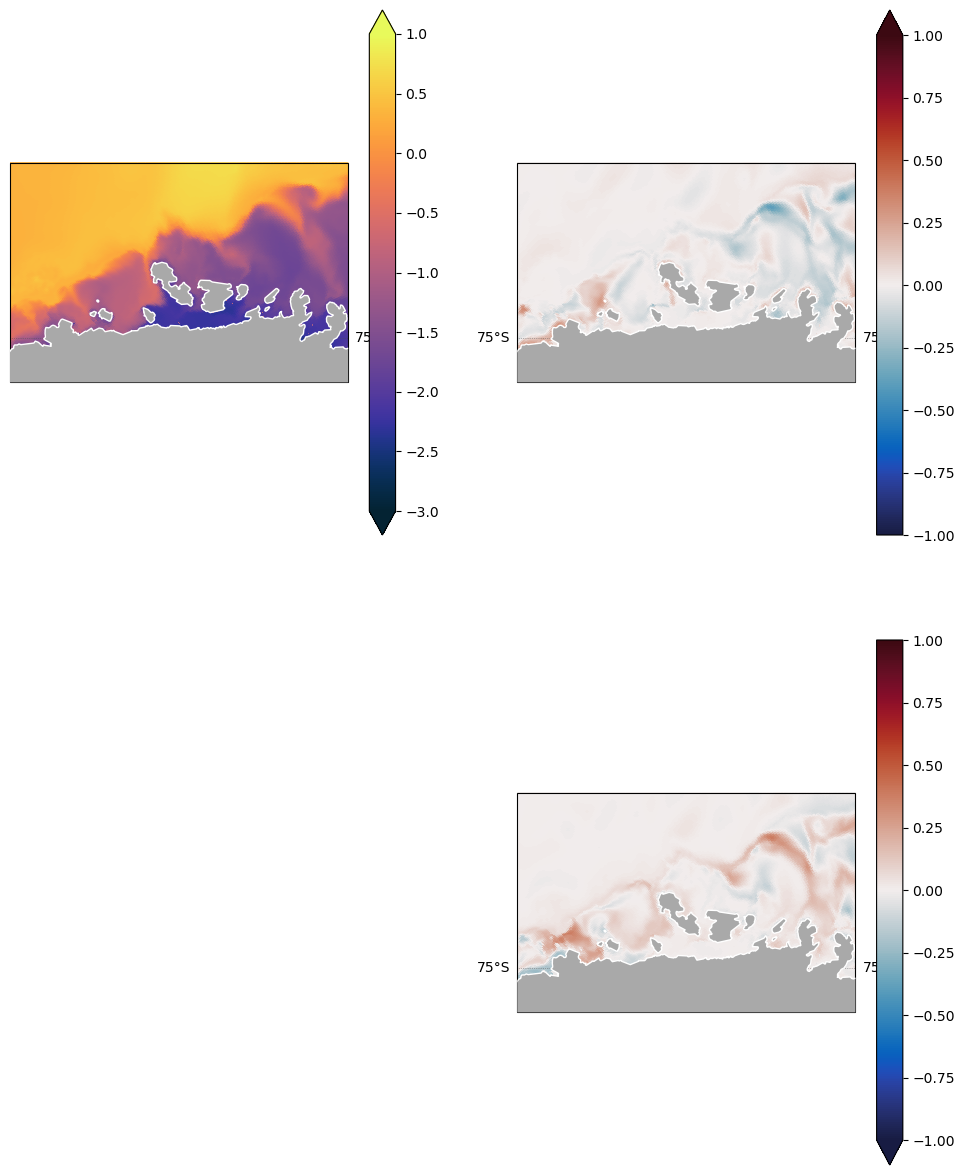

In [76]:
proj = ccrs.PlateCarree(central_longitude=0)

# extract temperature and depth for a given time
snapshot = WAOM4
temp_snapshot = snapshot['temp'].mean('time')
depth_snapshot = snapshot['z_rho'].mean('time')

# compute temperature at 100 meters depth using xgcm.transform
temp_500m_ANN = grid_waom4.transform(temp_snapshot, 'Z', np.array([200]),
                                target_data=depth_snapshot,
                                method='linear')

# plot results
fig = plt.figure(figsize=[12,15])
# ax = plt.axes(projection=proj)
ax = fig.add_subplot(2,2,1, projection=proj)
p = temp_500m_ANN.plot(ax=ax, x='lon_rho', y='lat_rho',
                   vmin=-3, vmax=1,
                   cmap=cmocean.cm.thermal,
                   add_labels=False,
                   transform=ccrs.PlateCarree())


gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,linewidth=.5, color=[.3,.3,.3], alpha=0.75, linestyle=':')
gl.xlines = True
gl.top_labels=False   # suppress top labels
gl.xlabels_bottom = True
gl.ylabels_left = False
gl.ylabels_right = True
gl.xlocator = mticker.FixedLocator([-180, -150, -100, -50, 0, 50, 100, 150, 180])
gl.ylocator = mticker.FixedLocator([-65, -70, -75, -80])
gl.xformatter = LONGITUDE_FORMATTER
gl.yformatter = LATITUDE_FORMATTER

ax.add_feature(cfeature.LAND, zorder=3, facecolor='darkgray',edgecolor='white')
ax.set_extent([-140, -110, -71, -76], crs=ccrs.PlateCarree())
x_left, x_right = ax.get_xlim()
y_low, y_high = ax.get_ylim()
ratio = .65  #.175

ax.set_aspect(abs((x_right-x_left)/(y_low-y_high))*ratio)


## --- 2ND panel: summer anomaly

# extract temperature and depth for a given time
snapshot = WAOM4.isel(time=slice(0,4))
temp_snapshot = snapshot['temp'].mean('time')
depth_snapshot = snapshot['z_rho'].mean('time')

# compute temperature at 100 meters depth using xgcm.transform
temp_500m_SUM = grid_waom4.transform(temp_snapshot, 'Z', np.array([200]),
                                target_data=depth_snapshot,
                                method='linear')
temp_SUM_anom = (temp_500m_SUM+273.15) - (temp_500m_ANN+273.15)

ax = fig.add_subplot(2,2,2, projection=proj)
p = temp_SUM_anom.plot(ax=ax, x='lon_rho', y='lat_rho',
                   vmin=-1, vmax=1,
                   cmap=cmocean.cm.balance,
                   add_labels=False,
                   transform=ccrs.PlateCarree())


gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,linewidth=.5, color=[.3,.3,.3], alpha=0.75, linestyle=':')
gl.xlines = True
gl.top_labels=False   # suppress top labels
# gl.xlabels_bottom = True
# gl.ylabels_left = False
# gl.ylabels_right = True
gl.xlocator = mticker.FixedLocator([-180, -150, -100, -50, 0, 50, 100, 150, 180])
gl.ylocator = mticker.FixedLocator([-65, -70, -75, -80])
gl.xformatter = LONGITUDE_FORMATTER
gl.yformatter = LATITUDE_FORMATTER

ax.add_feature(cfeature.LAND, zorder=3, facecolor='darkgray',edgecolor='white')
ax.set_extent([-140, -110, -71, -76], crs=ccrs.PlateCarree())
x_left, x_right = ax.get_xlim()
y_low, y_high = ax.get_ylim()
ratio = .65  #.175

ax.set_aspect(abs((x_right-x_left)/(y_low-y_high))*ratio)


## --- 2ND panel: winter anomaly

# extract temperature and depth for a given time
snapshot = WAOM4.isel(time=slice(5,9))
temp_snapshot = snapshot['temp'].mean('time')
depth_snapshot = snapshot['z_rho'].mean('time')

# compute temperature at 100 meters depth using xgcm.transform
temp_500m_WIN = grid_waom4.transform(temp_snapshot, 'Z', np.array([200]),
                                target_data=depth_snapshot,
                                method='linear')
temp_WIN_anom = (temp_500m_WIN+273.15) - (temp_500m_ANN+273.15)

ax = fig.add_subplot(2,2,4, projection=proj)
p = temp_WIN_anom.plot(ax=ax, x='lon_rho', y='lat_rho',
                   vmin=-1, vmax=1,
                   cmap=cmocean.cm.balance,
                   add_labels=False,
                   transform=ccrs.PlateCarree())


gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,linewidth=.5, color=[.3,.3,.3], alpha=0.75, linestyle=':')
gl.xlines = True
gl.top_labels=False   # suppress top labels
# gl.xlabels_bottom = True
# gl.ylabels_left = False
# gl.ylabels_right = True
gl.xlocator = mticker.FixedLocator([-180, -150, -100, -50, 0, 50, 100, 150, 180])
gl.ylocator = mticker.FixedLocator([-65, -70, -75, -80])
gl.xformatter = LONGITUDE_FORMATTER
gl.yformatter = LATITUDE_FORMATTER

ax.add_feature(cfeature.LAND, zorder=3, facecolor='darkgray',edgecolor='white')
ax.set_extent([-140, -110, -71, -76], crs=ccrs.PlateCarree())
x_left, x_right = ax.get_xlim()
y_low, y_high = ax.get_ylim()
ratio = .65  #.175

ax.set_aspect(abs((x_right-x_left)/(y_low-y_high))*ratio)

### Comparison with EN4 (addressing reviewer #2):

In [16]:
## load EN4:
EN4_path = '/g/data/gv90/fbd581/EN4/'

de = xr.open_mfdataset(EN4_path + '*.nc')#, parallel=bool, drop_variables=vars2drop, decode_times=False) #  chunks={'ocean_time': '200MB'}, concat_dim="ocean_time" 


In [17]:

# Define summer and winter months
summer_months = [12, 1, 2, 3, 4]
winter_months = [5, 6, 7, 8, 9, 10, 11]

In [18]:
# do climatological summer vs winter averages:
surface_temp = de.temperature.isel(depth=0)

# Filter the time range from 2000 to 2021
surface_temp = surface_temp.sel(time=slice('2000-01-01', '2021-12-31'))
# Select and average summer months
summer_data = surface_temp.sel(time=surface_temp.time.dt.month.isin(summer_months))
summer_climatology = summer_data.groupby('time.month').mean('time')
summer_mean = summer_climatology.mean('month')

# Select and average winter months
winter_data = surface_temp.sel(time=surface_temp.time.dt.month.isin(winter_months))
winter_climatology = winter_data.groupby('time.month').mean('time')
winter_mean = winter_climatology.mean('month')


In [31]:
## now do same average for temp_4km:
waom_temp = WAOM4.temp
waom_depth = WAOM4.z_rho

waom_temp_summer = waom_temp.sel(time=waom_temp.time.dt.month.isin(summer_months))
waom_temp_summer_mean = waom_temp_summer.mean('time')
# # define depth also:
waom_depth_summer = waom_depth.sel(time=waom_temp.time.dt.month.isin(summer_months))
waom_depth_summer_mean = waom_depth_summer.mean('time')

waom_temp_winter = waom_temp.sel(time=waom_temp.time.dt.month.isin(winter_months))
waom_temp_winter_mean = waom_temp_winter.mean('time')
# # define depth also:
waom_depth_winter = waom_depth.sel(time=waom_temp.time.dt.month.isin(winter_months))
waom_depth_winter_mean = waom_depth_winter.mean('time')

In [32]:
grid_waom4

<xgcm.Grid>
X Axis (not periodic, boundary=None):
  * center   xh --> outer
  * outer    xq --> center
Y Axis (not periodic, boundary=None):
  * center   yh --> outer
  * outer    yq --> center
Z Axis (not periodic, boundary=None):
  * center   s_rho --> outer
  * outer    s_w --> center

In [112]:
%%time
# convert WAOM to depth-levels:

# compute temperature at 100 meters depth using xgcm.transform
temp_summer_waom_0m = grid_waom4.transform(waom_temp_summer_mean, 'Z', np.array([0]),
                                target_data=waom_depth_summer_mean,
                                method='linear')
temp_summer_waom_50m = grid_waom4.transform(waom_temp_summer_mean, 'Z', np.array([-50]),
                                target_data=waom_depth_summer_mean,
                                method='linear')
temp_summer_waom_100m = grid_waom4.transform(waom_temp_summer_mean, 'Z', np.array([-100]),
                                target_data=waom_depth_summer_mean,
                                method='linear')
temp_summer_waom_150m = grid_waom4.transform(waom_temp_summer_mean, 'Z', np.array([-150]),
                                target_data=waom_depth_summer_mean,
                                method='linear')
temp_summer_waom_200m = grid_waom4.transform(waom_temp_summer_mean, 'Z', np.array([-200]),
                                target_data=waom_depth_summer_mean,
                                method='linear')


CPU times: user 61.4 ms, sys: 22 ms, total: 83.3 ms
Wall time: 76.2 ms


In [113]:
%%time
# convert WAOM to depth-levels:

# compute temperature at 100 meters depth using xgcm.transform
temp_winter_waom_0m = grid_waom4.transform(waom_temp_winter_mean, 'Z', np.array([0]),
                                target_data=waom_depth_winter_mean,
                                method='linear')
temp_winter_waom_50m = grid_waom4.transform(waom_temp_winter_mean, 'Z', np.array([-50]),
                                target_data=waom_depth_winter_mean,
                                method='linear')
temp_winter_waom_100m = grid_waom4.transform(waom_temp_winter_mean, 'Z', np.array([-100]),
                                target_data=waom_depth_winter_mean,
                                method='linear')
temp_winter_waom_150m = grid_waom4.transform(waom_temp_winter_mean, 'Z', np.array([-150]),
                                target_data=waom_depth_winter_mean,
                                method='linear')
temp_winter_waom_200m = grid_waom4.transform(waom_temp_winter_mean, 'Z', np.array([-200]),
                                target_data=waom_depth_winter_mean,
                                method='linear')


CPU times: user 42.9 ms, sys: 26.6 ms, total: 69.5 ms
Wall time: 71.3 ms


In [53]:
temp_summer_up200m = np.divide((temp_summer_waom_0m+temp_summer_waom_50m+
                      temp_summer_waom_100m+temp_summer_waom_150m+temp_summer_waom_200m),5).compute()

In [40]:
temp_winter_up200m = np.divide((temp_winter_waom_0m+temp_winter_waom_50m+
                      temp_winter_waom_100m+temp_winter_waom_150m+temp_winter_waom_200m),5).compute()

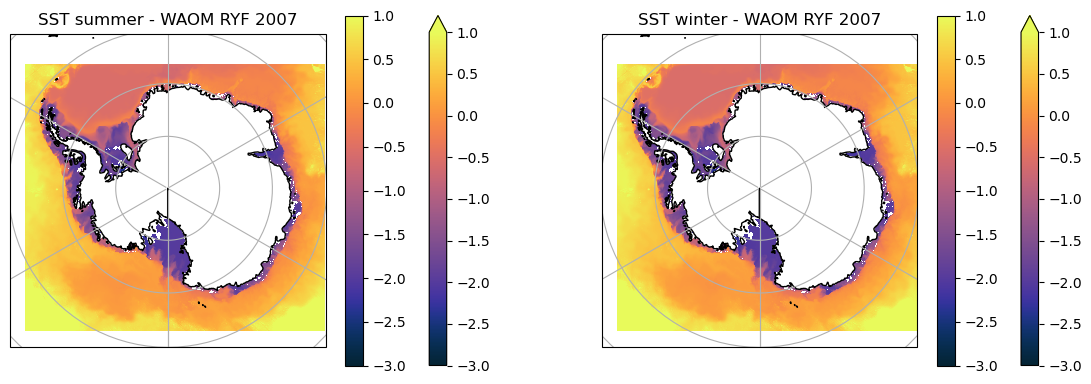

In [114]:
tmin=-2
tmax=3

# call cartopy projection
proj = ccrs.SouthPolarStereo()
fig = plt.figure(figsize=(14,10))

ax1 = fig.add_subplot(221, projection=proj)
# ct=plt.pcolormesh(lon_rho_4km,lat_rho_4km,waom_sst_summer_mean, transform=ccrs.PlateCarree(), cmap=cmocean.cm.thermal, vmin=tmin, vmax=tmax)#, shading='flat')
ct = temp_summer_waom_50m.plot(ax=ax1, x='lon_rho', y='lat_rho',
                   vmin=-3, vmax=1,
                   cmap=cmocean.cm.thermal,
                   add_labels=False,
                   transform=ccrs.PlateCarree())
cbart =fig.colorbar(ct)# , extend='both')
plt.title('SST summer - WAOM RYF 2007')
ax1.gridlines() # draw_labels=True,linewidth=2, color='gray', alpha=0.5, linestyle='--')
# ax1.coastlines(resolution='110m')
ax1.set_extent([-180, 180, -90, -60], crs=ccrs.PlateCarree())
ax1.add_feature(cfeature.LAND, zorder=1, edgecolor='black', facecolor='white')

ax1 = fig.add_subplot(222, projection=proj)
#ct=plt.pcolormesh(lon_rho_4km,lat_rho_4km,waom_sst_winter_mean, transform=ccrs.PlateCarree(), cmap=cmocean.cm.thermal, vmin=tmin, vmax=tmax)#, shading='flat')
ct = temp_winter_waom_50m.plot(ax=ax1, x='lon_rho', y='lat_rho',
                   vmin=-3, vmax=1,
                   cmap=cmocean.cm.thermal,
                   add_labels=False,
                   transform=ccrs.PlateCarree())
cbart =fig.colorbar(ct)# , extend='both')
plt.title('SST winter - WAOM RYF 2007')
ax1.gridlines() # draw_labels=True,linewidth=2, color='gray', alpha=0.5, linestyle='--')
# ax1.coastlines(resolution='110m')
ax1.set_extent([-180, 180, -90, -60], crs=ccrs.PlateCarree())
ax1.add_feature(cfeature.LAND, zorder=1, edgecolor='black', facecolor='white')

# ax1 = fig.add_subplot(223, projection=proj)
# ct=plt.pcolormesh(de.lon,de.lat,summer_mean-273.15, transform=ccrs.PlateCarree(), cmap=cmocean.cm.thermal, vmin=tmin, vmax=tmax)#, shading='flat')
# cbart =fig.colorbar(ct)# , extend='both')
# plt.title('SST summer - EN4 (2000-2021)')
# ax1.gridlines() # draw_labels=True,linewidth=2, color='gray', alpha=0.5, linestyle='--')
# # ax1.coastlines(resolution='110m')
# ax1.set_extent([-180, 180, -90, -60], crs=ccrs.PlateCarree())
# ax1.add_feature(cfeature.LAND, zorder=1, edgecolor='black', facecolor='white')

# ax1 = fig.add_subplot(224, projection=proj)
# ct=plt.pcolormesh(de.lon,de.lat,winter_mean-273.15, transform=ccrs.PlateCarree(), cmap=cmocean.cm.thermal, vmin=tmin, vmax=tmax)#, shading='flat')
# cbart =fig.colorbar(ct)# , extend='both')
# plt.title('SST winter - EN4 (2000-2021)')
# ax1.gridlines() # draw_labels=True,linewidth=2, color='gray', alpha=0.5, linestyle='--')
# # ax1.coastlines(resolution='110m')
# ax1.set_extent([-180, 180, -90, -60], crs=ccrs.PlateCarree())
# ax1.add_feature(cfeature.LAND, zorder=1, edgecolor='black', facecolor='white')

# name_fig='waom4_SST_vsEN4clim.png'
# plt.savefig(fig_path + name_fig, dpi=600, bbox_inches='tight')

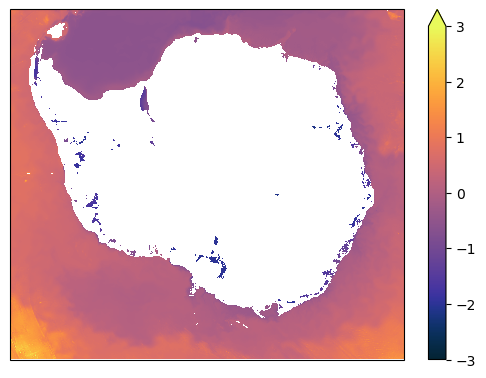

In [82]:
tmp = grid_waom4.transform(waom_temp, 'Z', np.array([-500]),
                                target_data=waom_depth,
                                method='linear')

proj = ccrs.SouthPolarStereo()
fig = plt.figure(figsize=(14,10))

ax1 = fig.add_subplot(221, projection=proj)
tmp.isel(time=1).plot(ax=ax1, x='lon_rho', y='lat_rho',
                   vmin=-3, vmax=3,
                   cmap=cmocean.cm.thermal,
                   add_labels=False,
                   transform=ccrs.PlateCarree())


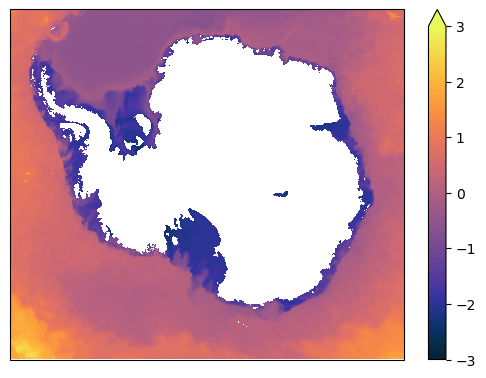

In [83]:
tmp = grid_waom4.transform(waom_temp, 'Z', np.array([-5]),
                                target_data=waom_depth,
                                method='linear')

proj = ccrs.SouthPolarStereo()
fig = plt.figure(figsize=(14,10))

ax1 = fig.add_subplot(221, projection=proj)
tmp.isel(time=1).plot(ax=ax1, x='lon_rho', y='lat_rho',
                   vmin=-3, vmax=3,
                   cmap=cmocean.cm.thermal,
                   add_labels=False,
                   transform=ccrs.PlateCarree())


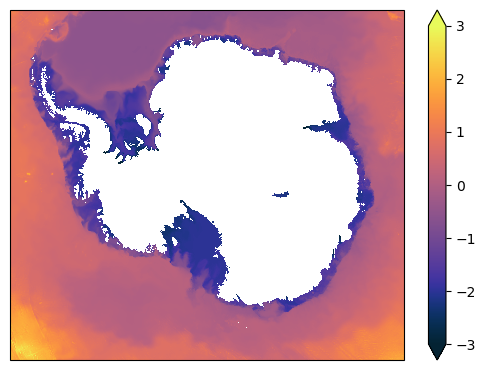

In [76]:
tmp = grid_waom4.transform(waom_temp_summer_mean, 'Z', np.array([10]),
                                target_data=waom_depth_summer_mean,
                                method='linear')

proj = ccrs.SouthPolarStereo()
fig = plt.figure(figsize=(14,10))

ax1 = fig.add_subplot(221, projection=proj)
tmp.plot(ax=ax1, x='lon_rho', y='lat_rho',
                   vmin=-3, vmax=3,
                   cmap=cmocean.cm.thermal,
                   add_labels=False,
                   transform=ccrs.PlateCarree())


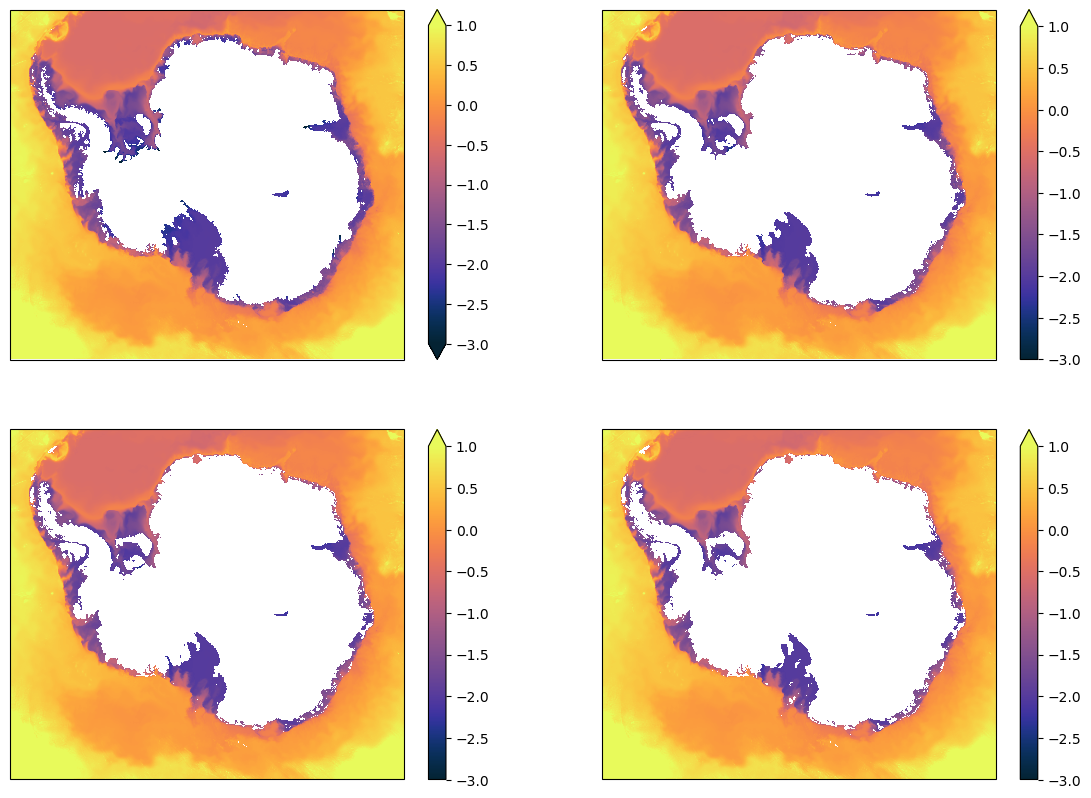

In [65]:
proj = ccrs.SouthPolarStereo()
fig = plt.figure(figsize=(14,10))

ax1 = fig.add_subplot(221, projection=proj)
temp_summer_waom_0m.plot(ax=ax1, x='lon_rho', y='lat_rho',
                   vmin=-3, vmax=1,
                   cmap=cmocean.cm.thermal,
                   add_labels=False,
                   transform=ccrs.PlateCarree())

ax1 = fig.add_subplot(222, projection=proj)
temp_summer_waom_50m.plot(ax=ax1, x='lon_rho', y='lat_rho',
                   vmin=-3, vmax=1,
                   cmap=cmocean.cm.thermal,
                   add_labels=False,
                   transform=ccrs.PlateCarree())
ax1 = fig.add_subplot(223, projection=proj)
temp_summer_waom_100m.plot(ax=ax1, x='lon_rho', y='lat_rho',
                   vmin=-3, vmax=1,
                   cmap=cmocean.cm.thermal,
                   add_labels=False,
                   transform=ccrs.PlateCarree())
ax1 = fig.add_subplot(224, projection=proj)
temp_summer_waom_150m.plot(ax=ax1, x='lon_rho', y='lat_rho',
                   vmin=-3, vmax=1,
                   cmap=cmocean.cm.thermal,
                   add_labels=False,
                   transform=ccrs.PlateCarree())

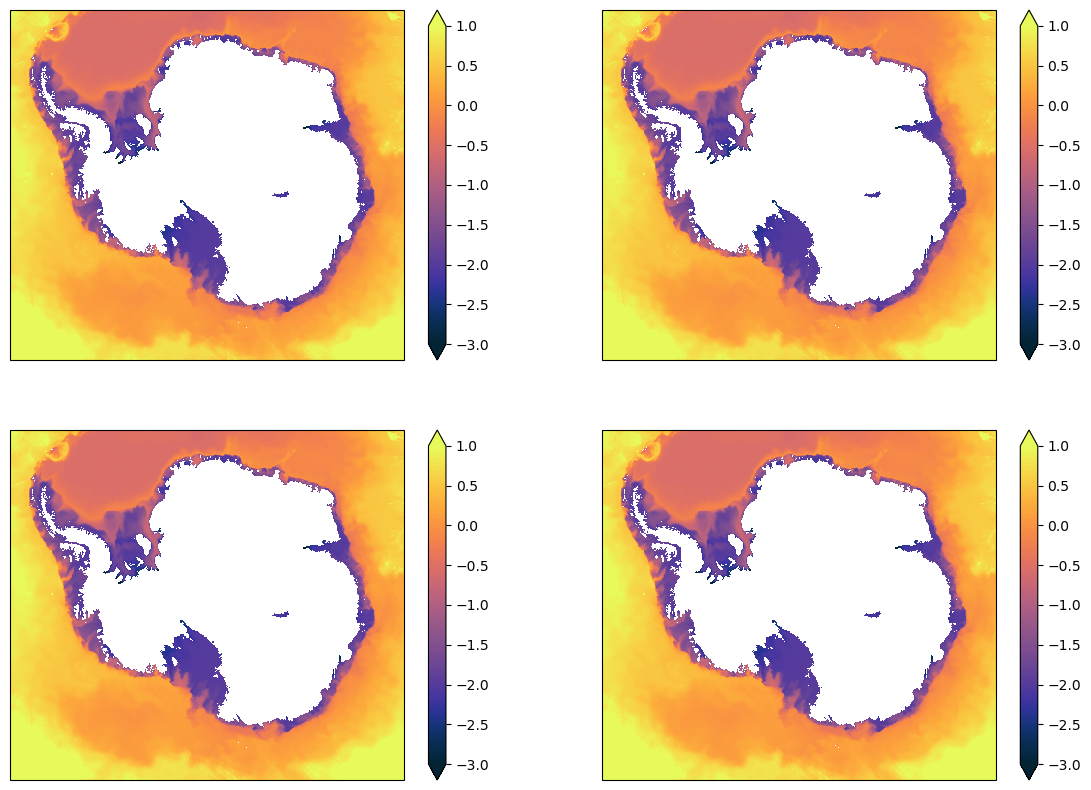

In [59]:
proj = ccrs.SouthPolarStereo()
fig = plt.figure(figsize=(14,10))

ax1 = fig.add_subplot(221, projection=proj)
temp_winter_waom_0m.plot(ax=ax1, x='lon_rho', y='lat_rho',
                   vmin=-3, vmax=1,
                   cmap=cmocean.cm.thermal,
                   add_labels=False,
                   transform=ccrs.PlateCarree())

ax1 = fig.add_subplot(222, projection=proj)
temp_winter_waom_50m.plot(ax=ax1, x='lon_rho', y='lat_rho',
                   vmin=-3, vmax=1,
                   cmap=cmocean.cm.thermal,
                   add_labels=False,
                   transform=ccrs.PlateCarree())
ax1 = fig.add_subplot(223, projection=proj)
temp_winter_waom_100m.plot(ax=ax1, x='lon_rho', y='lat_rho',
                   vmin=-3, vmax=1,
                   cmap=cmocean.cm.thermal,
                   add_labels=False,
                   transform=ccrs.PlateCarree())
ax1 = fig.add_subplot(224, projection=proj)
temp_winter_waom_150m.plot(ax=ax1, x='lon_rho', y='lat_rho',
                   vmin=-3, vmax=1,
                   cmap=cmocean.cm.thermal,
                   add_labels=False,
                   transform=ccrs.PlateCarree())

### Initial condition analyses for ACCESS-OM3:

<xarray.Dataset>
Dimensions:     (s_rho: 31, s_w: 32, time: 12, yh: 558, xh: 628, xq: 629,
                 yq: 559)
Coordinates: (12/14)
    Cs_r        (s_rho) float64 dask.array<chunksize=(31,), meta=np.ndarray>
    Cs_w        (s_w) float64 dask.array<chunksize=(32,), meta=np.ndarray>
    Vtransform  int32 ...
    h           (yh, xh) float64 dask.array<chunksize=(558, 628), meta=np.ndarray>
    hc          float64 ...
    lat_psi     (yq, xq) float64 dask.array<chunksize=(559, 629), meta=np.ndarray>
    ...          ...
    lat_v       (yq, xh) float64 dask.array<chunksize=(559, 628), meta=np.ndarray>
    lon_psi     (yq, xq) float64 dask.array<chunksize=(559, 629), meta=np.ndarray>
    lon_rho     (yh, xh) float64 dask.array<chunksize=(558, 628), meta=np.ndarray>
    lon_u       (yh, xq) float64 dask.array<chunksize=(558, 629), meta=np.ndarray>
    lon_v       (yq, xh) float64 dask.array<chunksize=(559, 628), meta=np.ndarray>
  * time        (time) datetime64[ns] 2007-01-16T05:00:00 ... 2007-12-16T19:0...
Dimensions without coordinates: s_rho, s_w, yh, xh, xq, yq
Data variables: (12/43)
    Hbbl        (time, yh, xh) float32 dask.array<chunksize=(1, 558, 628), meta=np.ndarray>
    Hsbl        (time, yh, xh) float32 dask.array<chunksize=(1, 558, 628), meta=np.ndarray>
    Huon        (time, s_rho, yh, xq) float32 dask.array<chunksize=(1, 31, 558, 629), meta=np.ndarray>
    Huon_salt   (time, s_rho, yh, xq) float32 dask.array<chunksize=(1, 31, 558, 629), meta=np.ndarray>
    Huon_temp   (time, s_rho, yh, xq) float32 dask.array<chunksize=(1, 31, 558, 629), meta=np.ndarray>
    Hvom        (time, s_rho, yq, xh) float32 dask.array<chunksize=(1, 31, 559, 628), meta=np.ndarray>
    ...          ...
    zeta        (time, yh, xh) float32 dask.array<chunksize=(1, 558, 628), meta=np.ndarray>
    zice        (yh, xh) float64 dask.array<chunksize=(558, 628), meta=np.ndarray>
    z_rho       (time, s_rho, yh, xh) float64 dask.array<chunksize=(1, 31, 558, 628), meta=np.ndarray>
    z_w         (time, s_w, yh, xh) float64 dask.array<chunksize=(1, 32, 558, 628), meta=np.ndarray>
    z_u         (time, s_rho, yh, xq) float64 dask.array<chunksize=(1, 31, 558, 629), meta=np.ndarray>
    z_v         (time, s_rho, yq, xh) float64 dask.array<chunksize=(1, 31, 559, 628), meta=np.ndarray>
Attributes: (12/34)
    CPP_options:       WAOM10extend, ADD_FSOBC, ADD_M2OBC, ANA_BSFLUX, ANA_BT...
    Conventions:       CF-1.4
    NLM_LBC:           \nEDGE:  WEST   SOUTH  EAST   NORTH  \nzeta:  Cha    C...
    ana_file:          ROMS/Functionals/ana_btflux.h, ROMS/Functionals/ana_sr...
    avg_base:          /scratch/gh9/fbd581/ROMS/waom10extend_shflim_S_0.25Q/o...
    bry_file:          /g/data3/hh5/tmp/access-om/fbd581/ROMS/waom10_frc/waom...
    ...                ...
    script_file:       
    svn_rev:           Unversioned directory
    svn_url:           https:://myroms.org/svn/src
    tiling:            018x016
    title:             Whole Antarctic and Ocean Application, 10 km resolution
    type:              ROMS/TOMS nonlinear model averages file

In [21]:
# output store name
store_name_yr1 = '/g/data/gv90/fbd581/ROMS/OUTPUT/waom10extend_shflim_S_0.25Q/output_01-20yr/WAOM10_store_yr01'


WAOM10_yr1 = xr.open_zarr(store_name_yr1, consolidated=True)

# Create xgcm grid object
grid_waom10_yr1 = Grid(WAOM10_yr1, coords={'X': {'center': 'xh', 'outer': 'xq'},
                               'Y': {'center': 'yh', 'outer': 'yq'},
                               'Z': {'center': 's_rho', 'outer': 's_w'}},
                 periodic=False)

# Add depths of layers and interfaces to dataset
WAOM10_yr1 = compute_depth_layers(WAOM10_yr1, grid_waom10_yr1)



DEBUG!
<xarray.DataArray 'z_rho' (time: 12, s_rho: 31, yh: 558, xh: 628)>
dask.array<where, shape=(12, 31, 558, 628), dtype=float64, chunksize=(1, 31, 558, 628), chunktype=numpy.ndarray>
Coordinates:
    Cs_r        (s_rho) float64 dask.array<chunksize=(31,), meta=np.ndarray>
    Vtransform  int32 ...
    h           (yh, xh) float64 dask.array<chunksize=(558, 628), meta=np.ndarray>
    hc          float64 ...
    lat_rho     (yh, xh) float64 dask.array<chunksize=(558, 628), meta=np.ndarray>
    lon_rho     (yh, xh) float64 dask.array<chunksize=(558, 628), meta=np.ndarray>
  * time        (time) datetime64[ns] 2007-01-16T05:00:00 ... 2007-12-16T19:0...
Dimensions without coordinates: s_rho, yh, xh
<xarray.DataArray 'z_u' (time: 12, s_rho: 31, yh: 558, xq: 629)>
dask.array<transpose, shape=(12, 31, 558, 629), dtype=float64, chunksize=(1, 31, 558, 629), chunktype=numpy.ndarray>
Coordinates:
    Cs_r        (s_rho) float64 dask.array<chunksize=(31,), meta=np.ndarray>
    Vtransform  int32

In [23]:
store_name_yr20 = '/g/data/gv90/fbd581/ROMS/OUTPUT/waom10extend_shflim_S_0.25Q/output_01-20yr/WAOM10_store_yr20'

WAOM10_yr20 = xr.open_zarr(store_name_yr20, consolidated=True)

# Create xgcm grid object
grid_waom10_yr20 = Grid(WAOM10_yr20, coords={'X': {'center': 'xh', 'outer': 'xq'},
                               'Y': {'center': 'yh', 'outer': 'yq'},
                               'Z': {'center': 's_rho', 'outer': 's_w'}},
                 periodic=False)

# Add depths of layers and interfaces to dataset
WAOM10_yr20 = compute_depth_layers(WAOM10_yr20, grid_waom10_yr20)


DEBUG!
<xarray.DataArray 'z_rho' (time: 12, s_rho: 31, yh: 558, xh: 628)>
dask.array<where, shape=(12, 31, 558, 628), dtype=float64, chunksize=(1, 31, 558, 628), chunktype=numpy.ndarray>
Coordinates:
    Cs_r        (s_rho) float64 dask.array<chunksize=(31,), meta=np.ndarray>
    Vtransform  int32 ...
    h           (yh, xh) float64 dask.array<chunksize=(558, 628), meta=np.ndarray>
    hc          float64 ...
    lat_rho     (yh, xh) float64 dask.array<chunksize=(558, 628), meta=np.ndarray>
    lon_rho     (yh, xh) float64 dask.array<chunksize=(558, 628), meta=np.ndarray>
  * time        (time) datetime64[ns] 2026-01-11T05:00:00 ... 2026-12-11T19:0...
Dimensions without coordinates: s_rho, yh, xh
<xarray.DataArray 'z_u' (time: 12, s_rho: 31, yh: 558, xq: 629)>
dask.array<transpose, shape=(12, 31, 558, 629), dtype=float64, chunksize=(1, 31, 558, 629), chunktype=numpy.ndarray>
Coordinates:
    Cs_r        (s_rho) float64 dask.array<chunksize=(31,), meta=np.ndarray>
    Vtransform  int32

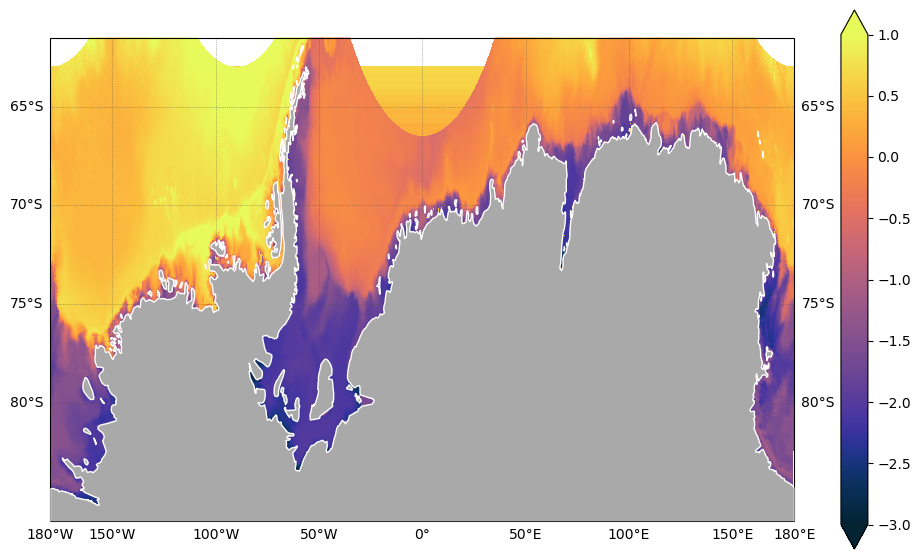

In [25]:
import matplotlib.ticker as mticker
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import cartopy.feature as cfeature

proj = ccrs.PlateCarree(central_longitude=0)

# extract temperature and depth for a given time
snapshot = WAOM10_yr1#.isel(time=7)
temp_snapshot = snapshot['temp'].mean('time')#.isel(time=0)
depth_snapshot = snapshot['z_rho'].mean('time')#.isel(time=0)

# compute temperature at 100 meters depth using xgcm.transform
temp_380m = grid_waom10.transform(temp_snapshot, 'Z', np.array([380]),
                                target_data=depth_snapshot,
                                method='linear')

# plot results
plt.figure(figsize=[12,7])
ax = plt.axes(projection=proj)
p = temp_380m.plot(ax=ax, x='lon_rho', y='lat_rho',
                   vmin=-3, vmax=1,
                   cmap=cmocean.cm.thermal,
                   add_labels=False,
                   transform=ccrs.PlateCarree())

# background
# url = 'http://map1c.vis.earthdata.nasa.gov/wmts-geo/wmts.cgi'
# p.axes.add_wmts(url, 'BlueMarble_NextGeneration')
# p.axes.set_extent([225,255,20,50])

# p.axes.set_extent([-180,180,-65,-90])

gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,linewidth=.5, color=[.3,.3,.3], alpha=0.75, linestyle=':')
gl.xlines = True
gl.top_labels=False   # suppress top labels
# gl.xlabels_bottom = True
# gl.ylabels_left = False
# gl.ylabels_right = True
gl.xlocator = mticker.FixedLocator([-180, -150, -100, -50, 0, 50, 100, 150, 180])
gl.ylocator = mticker.FixedLocator([-65, -70, -75, -80])
gl.xformatter = LONGITUDE_FORMATTER
gl.yformatter = LATITUDE_FORMATTER

ax.add_feature(cfeature.LAND, zorder=3, facecolor='darkgray',edgecolor='white')
ax.set_extent([-180, 180, -86, -61.5], crs=ccrs.PlateCarree())
x_left, x_right = ax.get_xlim()
y_low, y_high = ax.get_ylim()
ratio = .65  #.175

ax.set_aspect(abs((x_right-x_left)/(y_low-y_high))*ratio)

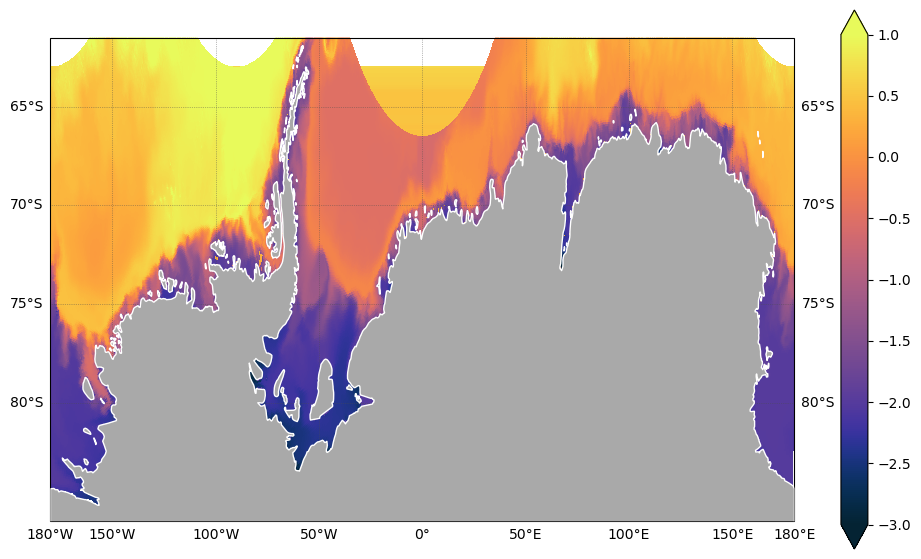

In [24]:
import matplotlib.ticker as mticker
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import cartopy.feature as cfeature

proj = ccrs.PlateCarree(central_longitude=0)

# extract temperature and depth for a given time
snapshot = WAOM10_yr20#.isel(time=7)
temp_snapshot = snapshot['temp'].mean('time')
depth_snapshot = snapshot['z_rho'].mean('time')

# compute temperature at 100 meters depth using xgcm.transform
temp_380m = grid_waom10.transform(temp_snapshot, 'Z', np.array([380]),
                                target_data=depth_snapshot,
                                method='linear')

# plot results
plt.figure(figsize=[12,7])
ax = plt.axes(projection=proj)
p = temp_380m.plot(ax=ax, x='lon_rho', y='lat_rho',
                   vmin=-3, vmax=1,
                   cmap=cmocean.cm.thermal,
                   add_labels=False,
                   transform=ccrs.PlateCarree())

# background
# url = 'http://map1c.vis.earthdata.nasa.gov/wmts-geo/wmts.cgi'
# p.axes.add_wmts(url, 'BlueMarble_NextGeneration')
# p.axes.set_extent([225,255,20,50])

# p.axes.set_extent([-180,180,-65,-90])

gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,linewidth=.5, color=[.3,.3,.3], alpha=0.75, linestyle=':')
gl.xlines = True
gl.top_labels=False   # suppress top labels
# gl.xlabels_bottom = True
# gl.ylabels_left = False
# gl.ylabels_right = True
gl.xlocator = mticker.FixedLocator([-180, -150, -100, -50, 0, 50, 100, 150, 180])
gl.ylocator = mticker.FixedLocator([-65, -70, -75, -80])
gl.xformatter = LONGITUDE_FORMATTER
gl.yformatter = LATITUDE_FORMATTER

ax.add_feature(cfeature.LAND, zorder=3, facecolor='darkgray',edgecolor='white')
ax.set_extent([-180, 180, -86, -61.5], crs=ccrs.PlateCarree())
x_left, x_right = ax.get_xlim()
y_low, y_high = ax.get_ylim()
ratio = .65  #.175

ax.set_aspect(abs((x_right-x_left)/(y_low-y_high))*ratio)